<a href="https://colab.research.google.com/github/tvml/ml2627/blob/master/codici/titanic.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# I sopravvissuti al disastro del Titanic

L'affondamento del RMS Titanic è uno dei naufragi più noti della storia. Il 15 aprile 1912, durante il viaggio inaugurale, il Titanic affondò dopo la collisione con un iceberg, causando la morte di 1502 delle 2224 persone a bordo tra passeggeri ed equipaggio. La tragedia sconvolse l'opinione pubblica internazionale e portò a norme di sicurezza più severe per le navi.

Uno dei motivi dell'alto numero di vittime fu la mancanza di scialuppe sufficienti per tutti. Sebbene la sopravvivenza dipendesse in parte dal caso, alcuni gruppi di persone ebbero probabilità di salvarsi molto maggiori di altri: in particolare le donne, i bambini e i passeggeri delle classi più alte, secondo la regola "prima le donne e i bambini" e per la diversa posizione delle cabine sulla nave.

In questo notebook analizziamo quali caratteristiche dei passeggeri sono associate alla sopravvivenza, e costruiamo dei **classificatori probabilistici** che stimano, per ogni passeggero, la probabilità di sopravvivere. Il percorso segue le note sui predittori per la classificazione:

- esplorazione dei dati e stima di probabilità condizionate;
- preparazione delle feature (valori mancanti, codifica delle variabili categoriche, selezione ed estrazione di feature);
- un primo classificatore, **Naive Bayes** gaussiano, e le **misure di qualità** di un classificatore binario: matrice di confusione, precision, recall, F-score, accuratezza, curva ROC e AUC;
- la scelta della **soglia** di decisione applicata alle probabilità;
- la valutazione corretta delle prestazioni, con test set e cross validation;
- la **regressione logistica**, con e senza regolarizzazione, e il confronto finale tra i modelli.

In [1]:
from IPython.display import Image
import warnings
warnings.filterwarnings('ignore')

%matplotlib inline

In [2]:
import numpy as np
import pandas as pd 
import scipy.stats as stats
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_validate, cross_val_predict, GridSearchCV, StratifiedKFold
from sklearn.feature_selection import mutual_info_classif, f_classif, SelectKBest
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import Pipeline
from sklearn.metrics import confusion_matrix, precision_score, recall_score, accuracy_score, roc_curve 
from sklearn.metrics import f1_score, precision_recall_fscore_support, roc_auc_score, make_scorer, auc
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import calibration_curve

Impostazione dello stile dei grafici. Usiamo **seaborn**, che costruisce su matplotlib grafici statistici con uno stile più curato e lavora direttamente con i `DataFrame` di pandas; matplotlib resta disponibile per le parti che seaborn non copre. Fissiamo un seme per rendere riproducibili partizioni e risultati.

In [3]:
import matplotlib as mpl
import matplotlib.pyplot as plt

sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.figsize'] = (16, 8)
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11

colors = ['xkcd:pale orange', 'xkcd:sea blue', 'xkcd:pale red', 'xkcd:sage green', 'xkcd:terra cotta', 'xkcd:dull purple', 'xkcd:teal', 'xkcd:goldenrod', 'xkcd:cadet blue', 
          'xkcd:scarlet']
# colori associati alle due classi: 0 = deceduto, 1 = sopravvissuto
pal = {0: colors[2], 1: colors[1]}
# mappa di colori per le heatmap (cm.get_cmap non esiste più nelle versioni recenti di matplotlib)
cmap_big = mpl.colormaps['Spectral'].resampled(512)
cmap = mpl.colors.ListedColormap(cmap_big(np.linspace(0.7, 0.95, 256)))

SEED = 0
np.random.seed(SEED)

In [ ]:
import urllib.request

filepath = "../dataset/"
url = "https://tvml.github.io/ml2627/dataset/"

def get_file(filename, local=True):
    IS_COLAB = ('google.colab' in str(get_ipython()))
    if IS_COLAB or not local:
        urllib.request.urlretrieve(url+filename, filename)
        return filename
    else:
        return filepath+filename

Diverse celle del notebook calcolano e visualizzano le stesse misure di qualità per classificatori diversi. Per evitare ripetizioni, definiamo qui alcune funzioni di supporto, il cui significato sarà discusso quando verranno usate per la prima volta:

- `plot_confusion` disegna una o più matrici di confusione;
- `report` stampa precision, recall e F-score per ciascuna classe e l'accuratezza;
- `plot_probabilita` mostra la distribuzione delle probabilità di sopravvivenza stimate, separatamente per i passeggeri sopravvissuti e deceduti, con la soglia di decisione.

Tutte le funzioni di scikit-learn che confrontano etichette vere e predette prendono come **primo argomento le etichette vere** e come secondo quelle predette: invertire l'ordine scambia, ad esempio, precision e recall.

In [5]:
def plot_confusion(cms, titles, cmaps=('PuBu', 'OrRd')):
    """Disegna una o più matrici di confusione (righe: classe vera, colonne: classe predetta)."""
    fig, axes = plt.subplots(1, len(cms), figsize=(7*len(cms), 4.5), squeeze=False)
    for ax, m, t, cm_name in zip(axes[0], cms, titles, cmaps):
        sns.heatmap(m, cbar=True, annot=True, square=True, fmt='d', annot_kws={'size': 14},
                    cmap=sns.color_palette(cm_name, 10), ax=ax,
                    xticklabels=['deceduto', 'sopravvissuto'], yticklabels=['deceduto', 'sopravvissuto'])
        ax.set_xlabel('classe predetta')
        ax.set_ylabel('classe vera')
        ax.set_title(t)
    plt.tight_layout()
    plt.show()

def report(y_true, y_pred, titolo=None):
    """Precision, recall e F-score per classe, e accuratezza."""
    m = precision_recall_fscore_support(y_true, y_pred)
    t = pd.DataFrame({'precision': m[0], 'recall': m[1], 'F-score': m[2], 'supporto': m[3]},
                     index=['classe 0 (deceduto)', 'classe 1 (sopravvissuto)'])
    if titolo: print(titolo)
    print(t.round(4).to_string())
    print('Accuratezza = {0:5.4f}'.format(accuracy_score(y_true, y_pred)))

def plot_probabilita(y_true, prob, soglia=.5, titolo=''):
    """Distribuzione delle probabilità stimate di sopravvivenza, per classe vera."""
    d = pd.DataFrame({'probabilità stimata di sopravvivenza': prob, 'classe vera': np.asarray(y_true)})
    plt.figure(figsize=(16, 6))
    sns.histplot(data=d, x='probabilità stimata di sopravvivenza', hue='classe vera', bins=40, palette=pal,
                 element='step', stat='count', common_norm=False, alpha=.4)
    plt.axvline(soglia, color=colors[9], ls='--', lw=2)
    plt.text(soglia, plt.ylim()[1]*.95, ' soglia {0:.3f}'.format(soglia), color=colors[9], va='top')
    plt.title(titolo)
    plt.show()

## Lettura ed esplorazione dei dati

Leggiamo il dataset in un `DataFrame` pandas.

In [9]:
df = pd.read_csv(get_file("titanic.csv", local=False))

Una prima visione dei dati:

In [10]:
df.head(20)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C


In [11]:
df.shape

(891, 12)

Il dataset contiene $891$ passeggeri (non tutti i $2224$ a bordo: è il *training set* della nota competizione Kaggle) e le seguenti feature:

- *PassengerId*: identificativo del passeggero
- *Survived*: sopravvivenza (0 = no; 1 = sì), il **target** da predire
- *Pclass*: classe del biglietto (1 = prima; 2 = seconda; 3 = terza)
- *Name*: nome
- *Sex*: sesso (female, male)
- *Age*: età in anni
- *SibSp*: numero di fratelli, sorelle o coniugi a bordo
- *Parch*: numero di genitori o figli a bordo
- *Ticket*: numero del biglietto
- *Fare*: prezzo del biglietto
- *Cabin*: cabina
- *Embarked*: porto di imbarco (C = Cherbourg; Q = Queenstown; S = Southampton)

In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


`info` mostra già un aspetto da affrontare: *Age*, *Cabin* ed *Embarked* hanno valori mancanti. Le feature sono di tipi diversi: alcune sono **categoriche** (*Sex*, *Embarked*, e, pur essendo rappresentata da un intero, *Pclass*), altre numeriche **discrete** (*SibSp*, *Parch*), altre ancora numeriche **continue** (*Age*, *Fare*).

Costruiamo una nuova feature, *Alone*, che vale $1$ per i passeggeri che viaggiavano senza familiari ($\textit{SibSp}+\textit{Parch}=0$): è un esempio di *feature engineering*, in cui una conoscenza del dominio (viaggiare da soli può aver cambiato il comportamento durante l'evacuazione) suggerisce una trasformazione delle feature esistenti.

In [13]:
df['TravelBuds'] = df["SibSp"]+df["Parch"]
df['Alone'] = np.where(df['TravelBuds']>0, 0, 1)
df.drop('TravelBuds', axis=1, inplace=True)

Per avere un primo quadro dei dati, visualizziamo la distribuzione di ciascuna feature: per le feature categoriche e discrete (`categ`) il numero di passeggeri per ogni valore, con un `countplot` di seaborn; per le due feature continue (`conti`), *Age* e *Fare*, un istogramma con una stima della densità.

Dai grafici emerge che:

- la maggior parte dei passeggeri viaggiava in terza classe, era di sesso maschile, si era imbarcata a Southampton e viaggiava da sola;
- solo circa il $38\%$ dei passeggeri del dataset è sopravvissuto: le classi del target non sono bilanciate;
- l'età non presenta valori anomali, mentre *Fare* ha una distribuzione molto asimmetrica, con la maggior parte dei valori tra $0$ e $100$ e pochi valori molto più grandi.

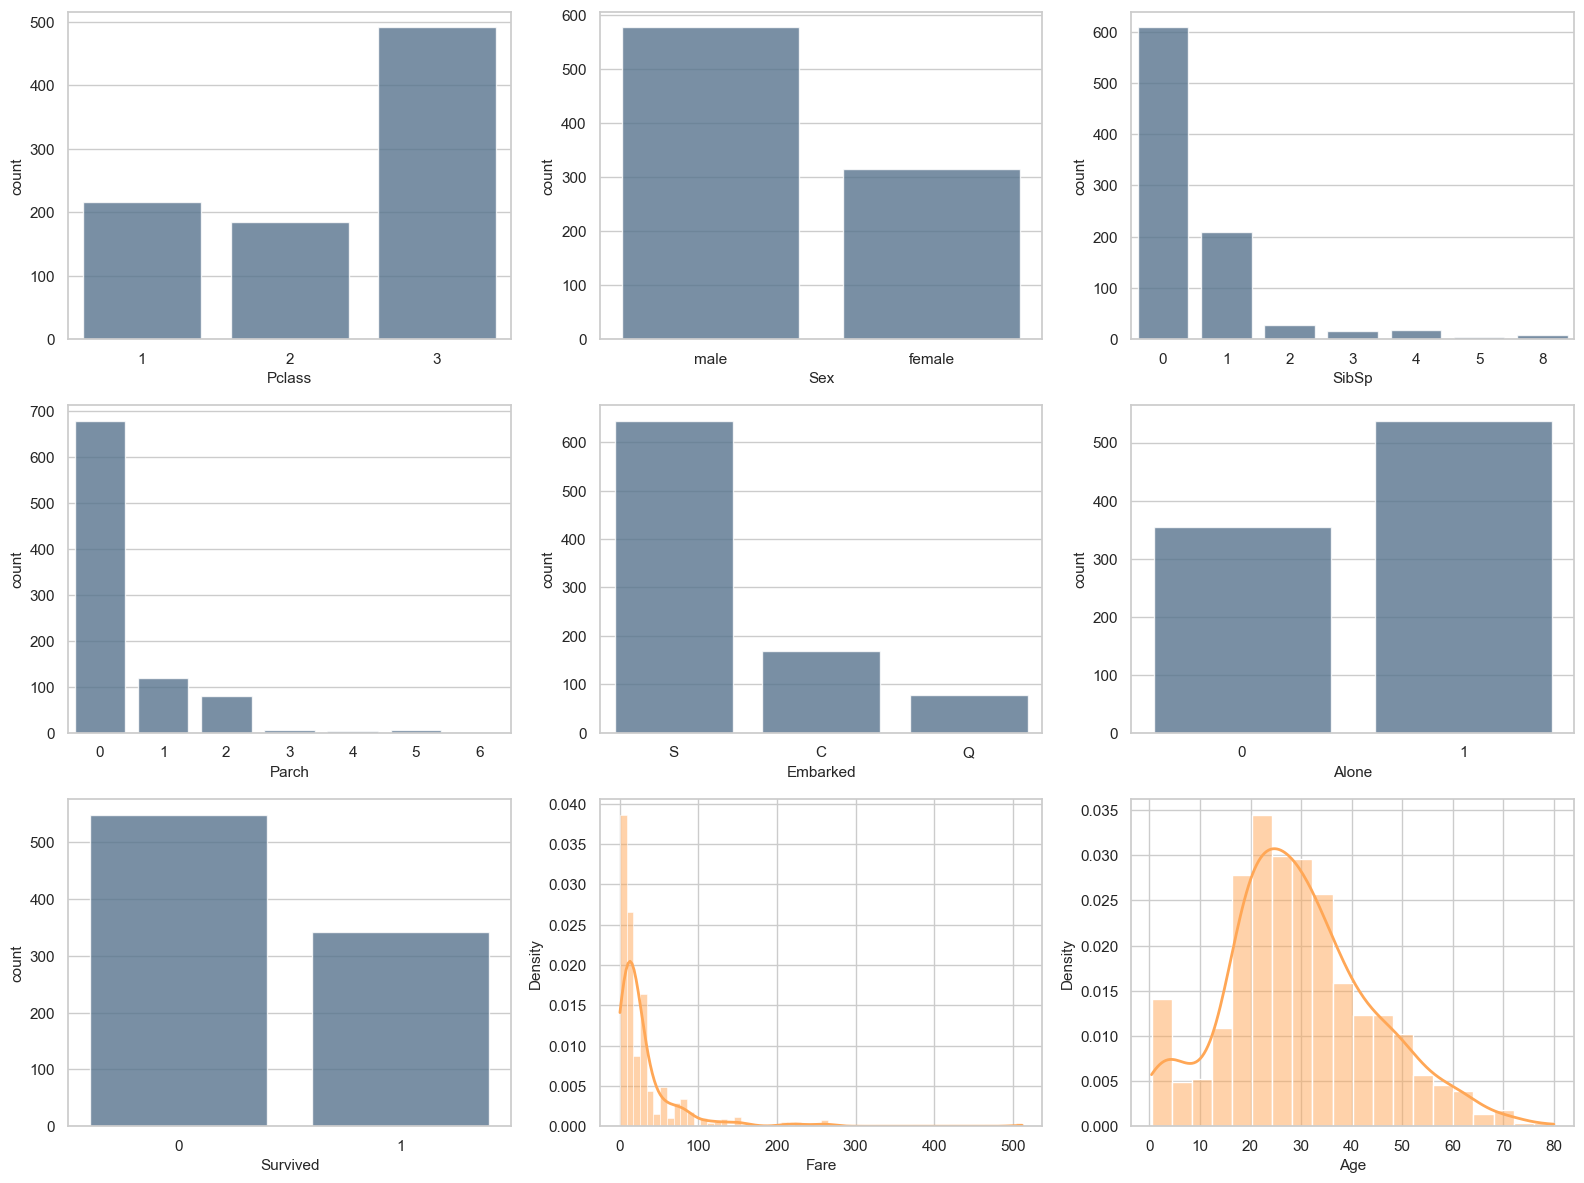

In [14]:
categ = ['Pclass', 'Sex', 'SibSp', 'Parch', 'Embarked', 'Alone', 'Survived']
conti = ['Fare', 'Age']

fig, axes = plt.subplots(3, 3, figsize=(16, 12))
axes = axes.ravel()
for ax, col in zip(axes, categ):
    sns.countplot(x=col, data=df, color=colors[8], alpha=.8, ax=ax)
for ax, col in zip(axes[len(categ):], conti):
    sns.histplot(df[col].dropna(), kde=True, stat='density', color=colors[0], line_kws={'lw': 2}, ax=ax)
plt.tight_layout()
plt.show()

Le stesse distribuzioni, separate tra sopravvissuti (1) e deceduti (0). Già da questi grafici si intuiscono le feature più rilevanti: la proporzione di sopravvissuti è molto diversa tra uomini e donne e tra le tre classi. Per l'età, la differenza principale riguarda i bambini, tra i quali i sopravvissuti sono in proporzione più numerosi; i *violin plot* di *Fare* mostrano che i sopravvissuti avevano pagato in media biglietti più costosi, un effetto legato alla classe.

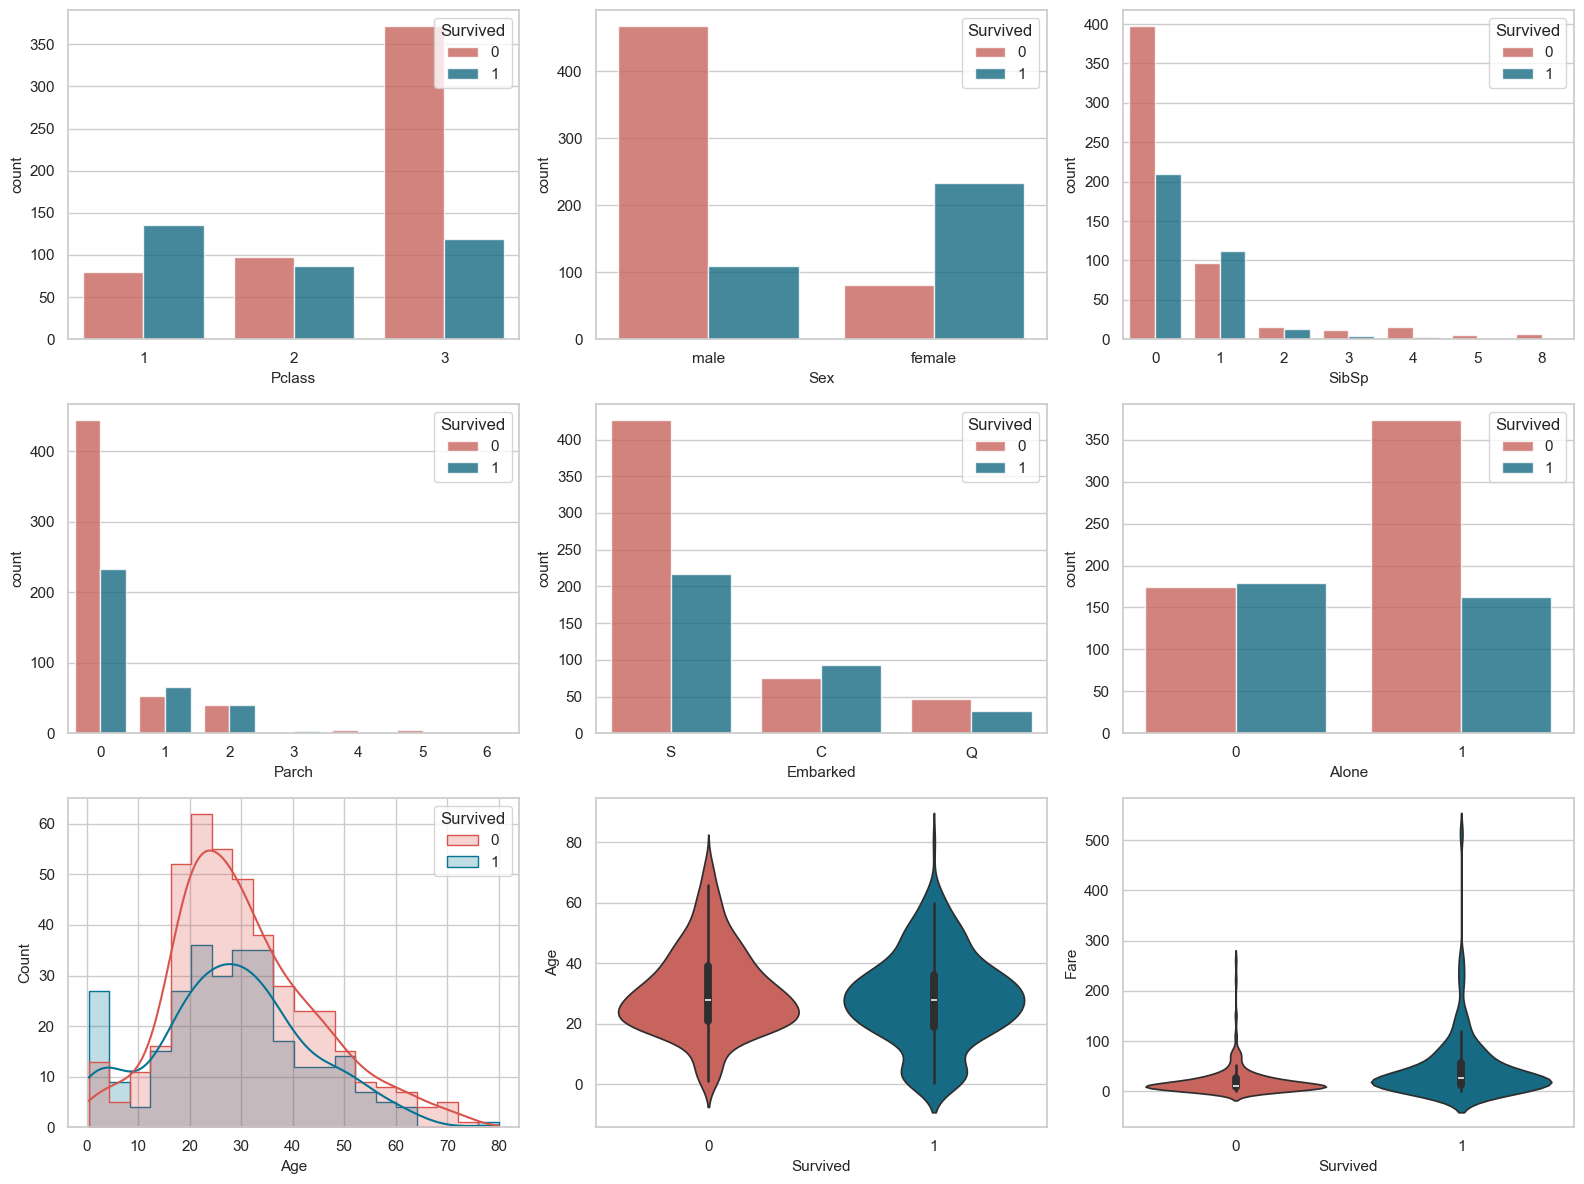

In [15]:
fig, axes = plt.subplots(3, 3, figsize=(16, 12))
axes = axes.ravel()
for ax, col in zip(axes, [c for c in categ if c != 'Survived']):
    sns.countplot(x=col, data=df, hue='Survived', palette=pal, alpha=.8, ax=ax)
    ax.legend(title='Survived', loc=1)

sns.histplot(data=df, x='Age', hue='Survived', palette=pal, kde=True, bins=20, element='step', ax=axes[6])
sns.violinplot(x='Survived', y='Age', data=df, hue='Survived', palette=pal, legend=False, ax=axes[7])
sns.violinplot(x='Survived', y='Fare', data=df, hue='Survived', palette=pal, legend=False, ax=axes[8])
plt.tight_layout()
plt.show()

### Probabilità condizionate di sopravvivenza

Stimiamo la probabilità di sopravvivenza condizionata al valore di una feature, $p(\textit{Survived}=1\mid \textit{feature}=v)$, con la frequenza relativa dei sopravvissuti tra i passeggeri con quel valore:
$$\hat p(\textit{Survived}=1\mid x=v)=\frac{|\{i: x_i=v,\ t_i=1\}|}{|\{i: x_i=v\}|}.$$
È la stima di massima verosimiglianza della probabilità di una Bernoulli, ristretta al sottoinsieme dei passeggeri con $x=v$. Va interpretata con cautela quando il sottoinsieme è piccolo (ad esempio per valori alti di *SibSp* o *Parch*): la stima ha allora una varianza elevata. Per questo motivo `cond_prob` restituisce anche il numero di passeggeri su cui la stima è calcolata.

In [16]:
def cond_prob(feature):
    """Stima di p(Survived=1 | feature=v) per ogni valore v della feature."""
    g = df[df[feature].notnull()].groupby(feature)['Survived']
    return pd.DataFrame({'value': g.mean().index, 'prob': g.mean().values, 'n': g.size().values})

def cond_prob_2(feature1, feature2):
    """Stima di p(Survived=1 | feature1=v1, feature2=v2) per ogni coppia di valori."""
    g = df[df[feature1].notnull() & df[feature2].notnull()].groupby([feature1, feature2])['Survived']
    return g.agg(prob='mean', n='size').reset_index()

La probabilità di sopravvivenza condizionata congiuntamente al sesso e alla classe mostra quanto i due fattori siano entrambi determinanti: quasi tutte le donne di prima e seconda classe si salvarono, contro meno del $15\%$ degli uomini di seconda e terza classe.

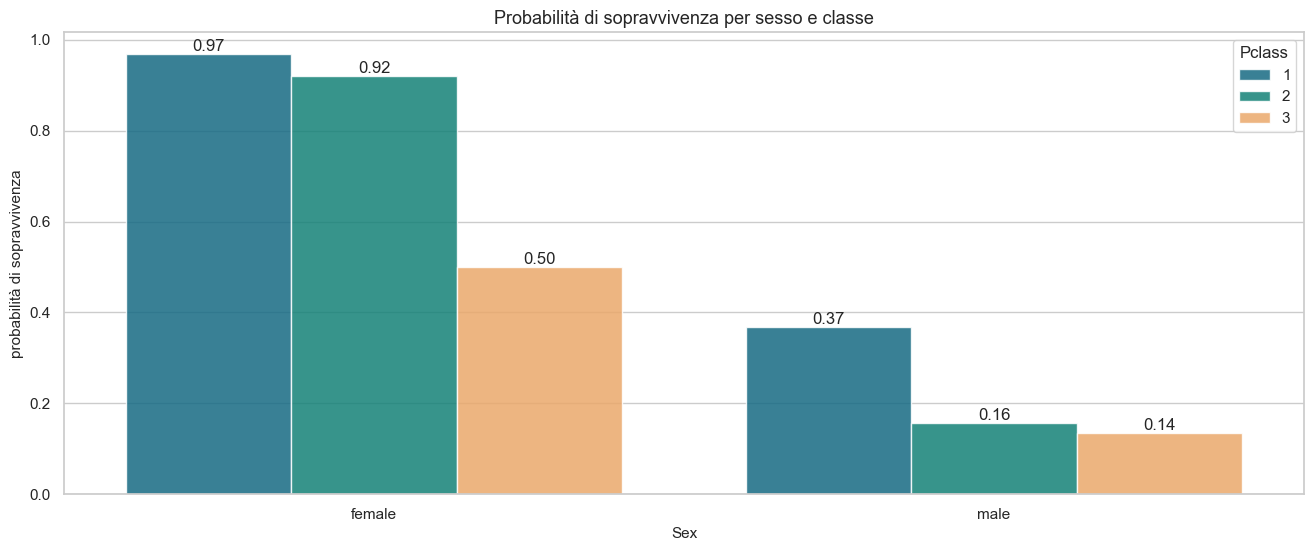

,Sex,Pclass,prob,n
0,female,1,0.968085,94
1,female,2,0.921053,76
2,female,3,0.500000,144
3,male,1,0.368852,122
4,male,2,0.157407,108
5,male,3,0.135447,347


In [17]:
cp = cond_prob_2('Sex', 'Pclass')
plt.figure(figsize=(16, 6))
ax = sns.barplot(x='Sex', y='prob', hue='Pclass', data=cp, palette=[colors[1], colors[6], colors[0]], alpha=.85)
for cont in ax.containers:
    ax.bar_label(cont, fmt='%.2f')
plt.ylabel('probabilità di sopravvivenza')
plt.title('Probabilità di sopravvivenza per sesso e classe')
plt.show()
cp

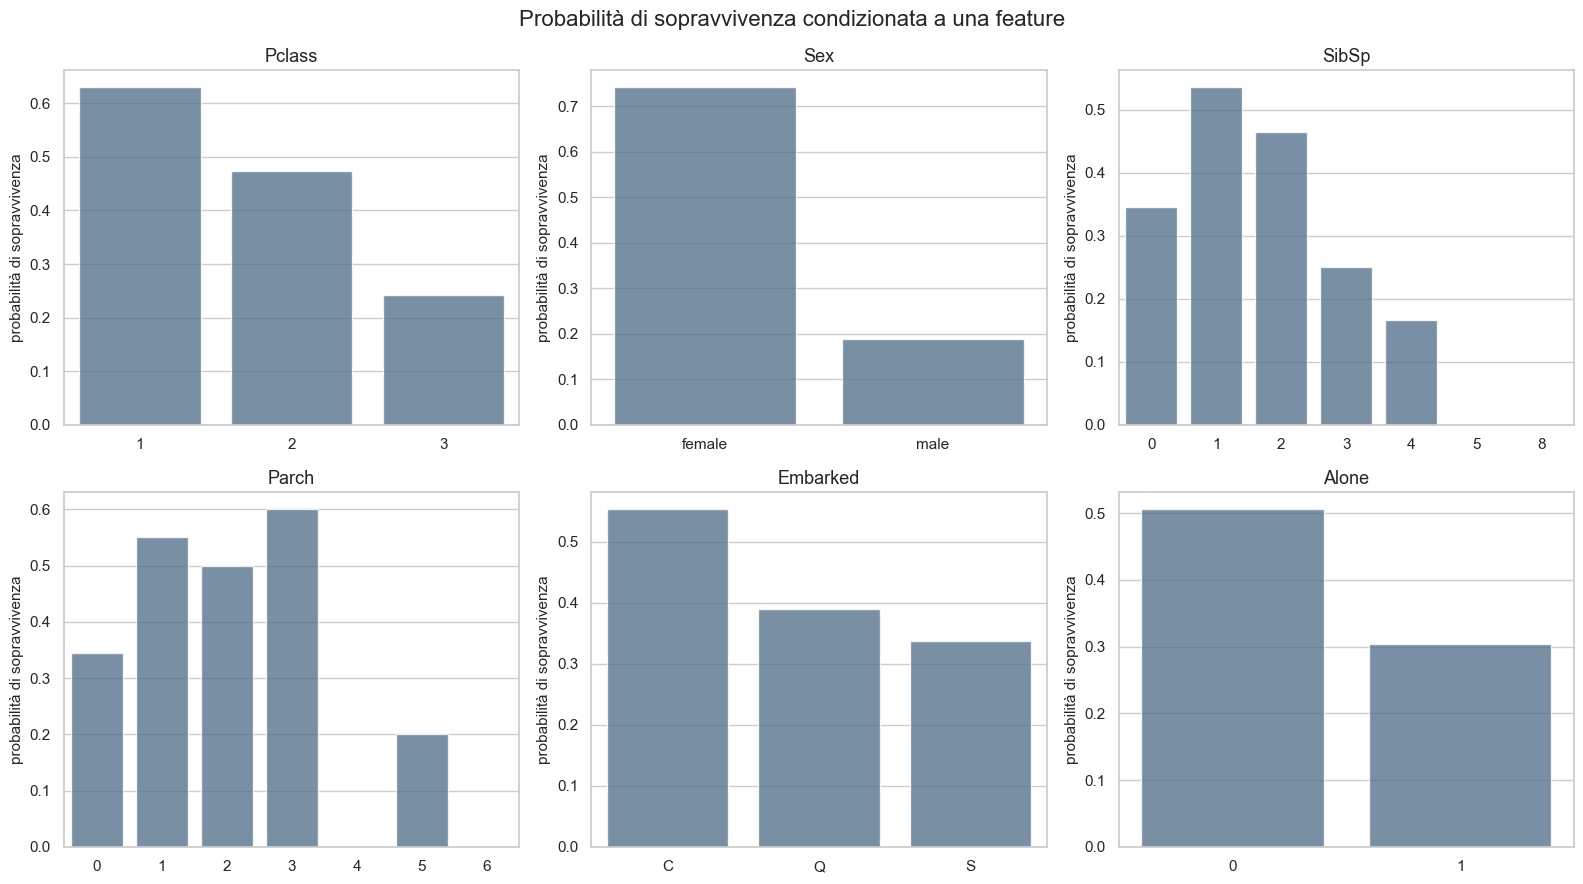

In [18]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.ravel(), [c for c in categ if c != 'Survived']):
    sns.barplot(x='value', y='prob', data=cond_prob(col), color=colors[8], alpha=.8, ax=ax)
    ax.set_title(col)
    ax.set_xlabel('')
    ax.set_ylabel('probabilità di sopravvivenza')
plt.suptitle('Probabilità di sopravvivenza condizionata a una feature', fontsize=16)
plt.tight_layout()
plt.show()

Per le feature continue la probabilità condizionata a un singolo valore non si può stimare per conteggio, perché quasi ogni valore compare una sola volta. Discretizziamo allora *Age* e *Fare* in intervalli, e stimiamo la probabilità di sopravvivenza in ciascun intervallo, globalmente e separatamente per uomini e donne.

Per l'età, la probabilità di sopravvivenza dei bambini (sotto i $10$ anni) è alta per entrambi i sessi, mentre per gli adulti la differenza tra uomini e donne è enorme. Per il prezzo del biglietto, la probabilità cresce con il prezzo, soprattutto per le donne. Gli intervalli più estremi contengono pochi passeggeri, e le stime corrispondenti sono poco affidabili.

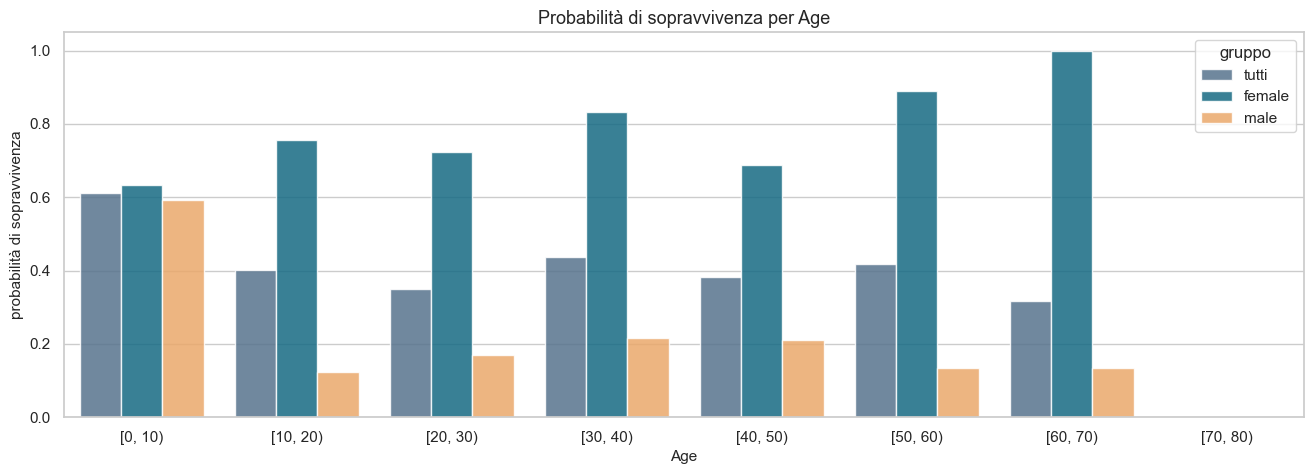

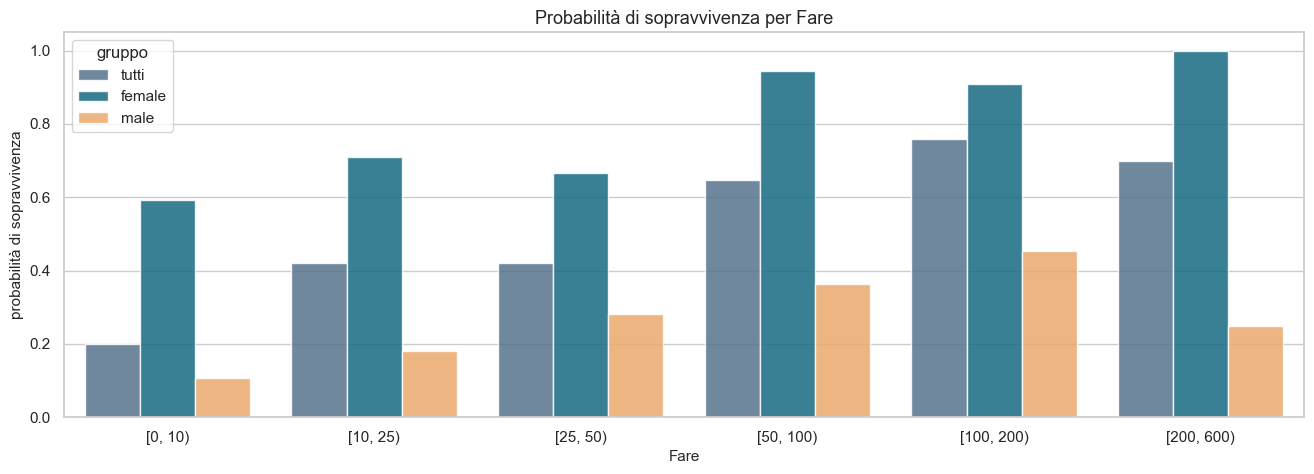

In [19]:
def prob_per_intervallo(col, bins):
    """Probabilità di sopravvivenza per intervalli di una feature continua, globale e per sesso."""
    d = df[df[col].notnull()].copy()
    d['intervallo'] = pd.cut(d[col], bins=bins, right=False)
    tot = d.groupby('intervallo', observed=False)['Survived'].mean().reset_index().assign(gruppo='tutti')
    sex = d.groupby(['intervallo', 'Sex'], observed=False)['Survived'].mean().reset_index().rename(columns={'Sex': 'gruppo'})
    res = pd.concat([tot, sex], ignore_index=True)
    res['intervallo'] = res['intervallo'].astype(str)
    return res

for col, bins in (('Age', range(0, 90, 10)), ('Fare', [0, 10, 25, 50, 100, 200, 600])):
    res = prob_per_intervallo(col, bins)
    plt.figure(figsize=(16, 5))
    sns.barplot(data=res, x='intervallo', y='Survived', hue='gruppo', palette=[colors[8], colors[1], colors[0]], alpha=.85)
    plt.ylabel('probabilità di sopravvivenza')
    plt.xlabel(col)
    plt.title('Probabilità di sopravvivenza per {0}'.format(col))
    plt.show()

## Preparazione delle feature

Eliminiamo innanzitutto le feature chiaramente non legate alla probabilità di sopravvivenza, o non utilizzabili direttamente: *PassengerId* è solo un identificativo, *Name* e *Ticket* sono stringhe quasi tutte diverse tra loro. (Da *Name* si potrebbe estrarre il titolo, come *Mr*, *Mrs*, *Miss*, *Master*, che porta informazione su sesso, età e stato civile: è un'estensione interessante, che qui non sviluppiamo.)

In [20]:
df = df.drop(['PassengerId', 'Name', 'Ticket'], axis=1) 
df.columns

Index(['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Cabin',
       'Embarked', 'Alone'],
      dtype='object')

### Valori mancanti

Le feature con valori mancanti sono:

In [21]:
df.columns[df.isna().any()].tolist()

['Age', 'Cabin', 'Embarked']

*Age* ha circa il $20\%$ di valori mancanti: troppi per eliminare i passeggeri corrispondenti, ma pochi abbastanza da poterli sostituire con un valore ragionevole (**imputazione**).

In [22]:
print('Numero di valori mancanti: {0:d}'.format(df['Age'].isna().sum()))
print('Frazione di valori mancanti: {0:5.3f}'.format(df['Age'].isna().mean()))

Numero di valori mancanti: 177
Frazione di valori mancanti: 0.199


Esaminiamo la distribuzione delle età disponibili:

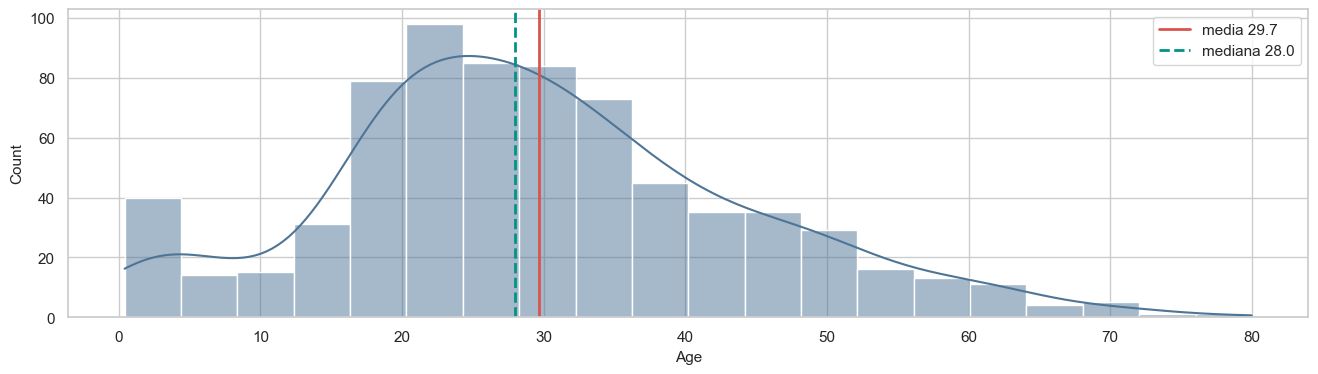

In [23]:
plt.figure(figsize=(16, 4))
sns.histplot(df['Age'].dropna(), kde=True, bins=20, color=colors[8])
plt.axvline(df['Age'].mean(), color=colors[2], lw=2, label='media {0:.1f}'.format(df['Age'].mean()))
plt.axvline(df['Age'].median(), color=colors[6], lw=2, ls='--', label='mediana {0:.1f}'.format(df['Age'].median()))
plt.legend()
plt.show()

La distribuzione di *Age* è asimmetrica a destra: la media è spostata verso le età più alte rispetto al valore tipico, per cui usiamo la **mediana**, meno sensibile alle code, per sostituire i valori mancanti.

Due osservazioni su questa scelta. Sostituire tutti i valori mancanti con lo stesso numero riduce artificialmente la varianza di *Age* e crea un picco nella sua distribuzione; un'imputazione più accurata userebbe le altre feature (ad esempio la mediana per classe e sesso, o il titolo estratto dal nome). Inoltre, calcolare la mediana sull'intero dataset prima di separare training e test set fa trapelare una (minima) informazione dal test set nell'apprendimento: in un'analisi rigorosa l'imputazione andrebbe inserita nella pipeline, con un `SimpleImputer`, in modo da essere stimata sul solo training set.

In [24]:
df['Age'] = df['Age'].fillna(df['Age'].median(skipna=True))

*Cabin* ha una quantità molto maggiore di valori mancanti:

In [25]:
print('Numero di valori mancanti: {0:d}'.format(df['Cabin'].isna().sum()))
print('Frazione di valori mancanti: {0:5.3f}'.format(df['Cabin'].isna().mean()))

Numero di valori mancanti: 687
Frazione di valori mancanti: 0.771


Con oltre il $75\%$ dei valori mancanti, un'imputazione non avrebbe senso: eliminiamo la feature. Si noti però che la *mancanza* stessa del dato può essere informativa: la cabina è registrata soprattutto per i passeggeri di prima classe, e una feature binaria "cabina nota" sarebbe correlata con la classe e quindi con la sopravvivenza.

In [26]:
df = df.drop(['Cabin'], axis=1) 
df.shape

(891, 9)

*Embarked* ha solo due valori mancanti:

In [27]:
print('Numero di valori mancanti: {0:d}'.format(df['Embarked'].isna().sum()))
print('Frazione di valori mancanti: {0:5.3f}'.format(df['Embarked'].isna().mean()))

Numero di valori mancanti: 2
Frazione di valori mancanti: 0.002


Trattandosi di una feature categorica, sostituiamo i valori mancanti con la classe più frequente (la *moda*). Attenzione: `value_counts().argmax()` restituirebbe la *posizione* del valore più frequente (cioè $0$), non il valore stesso; il valore si ottiene con `idxmax()`.

In [28]:
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].value_counts().idxmax())
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survived  891 non-null    int64  
 1   Pclass    891 non-null    int64  
 2   Sex       891 non-null    object 
 3   Age       891 non-null    float64
 4   SibSp     891 non-null    int64  
 5   Parch     891 non-null    int64  
 6   Fare      891 non-null    float64
 7   Embarked  891 non-null    object 
 8   Alone     891 non-null    int64  
dtypes: float64(2), int64(5), object(2)
memory usage: 62.8+ KB


### Codifica one-hot delle variabili categoriche

I classificatori di scikit-learn richiedono feature numeriche. Le variabili categoriche *Sex*, *Embarked* e *Pclass* vengono rappresentate con la **codifica one-hot**: una feature con $K$ valori è sostituita da $K$ feature binarie, ciascuna uguale a $1$ se il passeggero ha il valore corrispondente. Con `drop_first=True` si elimina la prima di esse, che è ridondante (è determinata dalle altre $K-1$): una colonna in più renderebbe le feature linearmente dipendenti, insieme al termine costante del modello.

*Pclass* è un intero, e potrebbe essere usata così com'è; trattarla come categorica permette invece al modello di assegnare un effetto diverso a ciascuna classe, senza imporre che la differenza tra prima e seconda classe sia uguale a quella tra seconda e terza.

In [29]:
df = pd.get_dummies(df, drop_first=True, columns=['Sex', 'Embarked', 'Pclass'], dtype=int)
df.head()

,Survived,Age,SibSp,Parch,Fare,Alone,Sex_male,Embarked_Q,Embarked_S,Pclass_2,Pclass_3
0,0,22.0,1,0,7.2500,0,1,0,1,0,1
1,1,38.0,1,0,71.2833,0,0,0,0,0,0
2,1,26.0,0,0,7.9250,1,0,0,1,0,1
3,1,35.0,1,0,53.1000,0,0,0,1,0,0
4,0,35.0,0,0,8.0500,1,1,0,1,0,1


### Bilanciamento delle classi

Verifichiamo quanto le due classi del target siano bilanciate.

In [30]:
print('Numero di elementi positivi (sopravvissuti): {0:d}'.format((df.Survived==1).sum()))
print('Numero di elementi negativi (deceduti): {0:d}'.format((df.Survived==0).sum()))
print('Frazione di elementi positivi: {0:3.2f}'.format(df.Survived.mean()))

Numero di elementi positivi (sopravvissuti): 342
Numero di elementi negativi (deceduti): 549
Frazione di elementi positivi: 0.38


C'è un certo sbilanciamento verso i negativi, che consideriamo accettabile. Va però tenuto presente nel valutare i risultati: un classificatore banale, che predice sempre "deceduto", ha già un'accuratezza del $62\%$, e qualunque modello va confrontato con questo valore di riferimento. Le misure come precision, recall e AUC, introdotte più avanti, sono più informative dell'accuratezza in presenza di classi sbilanciate.

Ricaviamo la matrice delle feature e il vettore dei target, e una versione standardizzata delle feature (media $0$ e varianza $1$ per ogni colonna), usata nell'analisi delle feature.

In [31]:
X = df.drop(['Survived'], axis=1)
y = df['Survived']
scaler = StandardScaler().fit(X)
X_s = pd.DataFrame(scaler.transform(X), columns=X.columns)
X.columns.tolist()

['Age',
 'SibSp',
 'Parch',
 'Fare',
 'Alone',
 'Sex_male',
 'Embarked_Q',
 'Embarked_S',
 'Pclass_2',
 'Pclass_3']

## Selezione ed estrazione di feature

Ridurre il numero di feature può migliorare la generalizzazione, eliminando feature irrilevanti che aggiungono solo rumore, e rende il modello più semplice da interpretare. Confrontiamo tre criteri per valutare la rilevanza delle feature, di natura diversa.

Il primo è l'**importanza** misurata da un insieme di alberi di decisione (*extra trees*, che vedremo più avanti nel corso): ogni albero sceglie, a ogni nodo, la feature che separa meglio le classi, e l'importanza di una feature è la riduzione di impurità complessiva ottenuta con essa. Le barre di errore mostrano la variabilità dell'importanza tra i $250$ alberi.

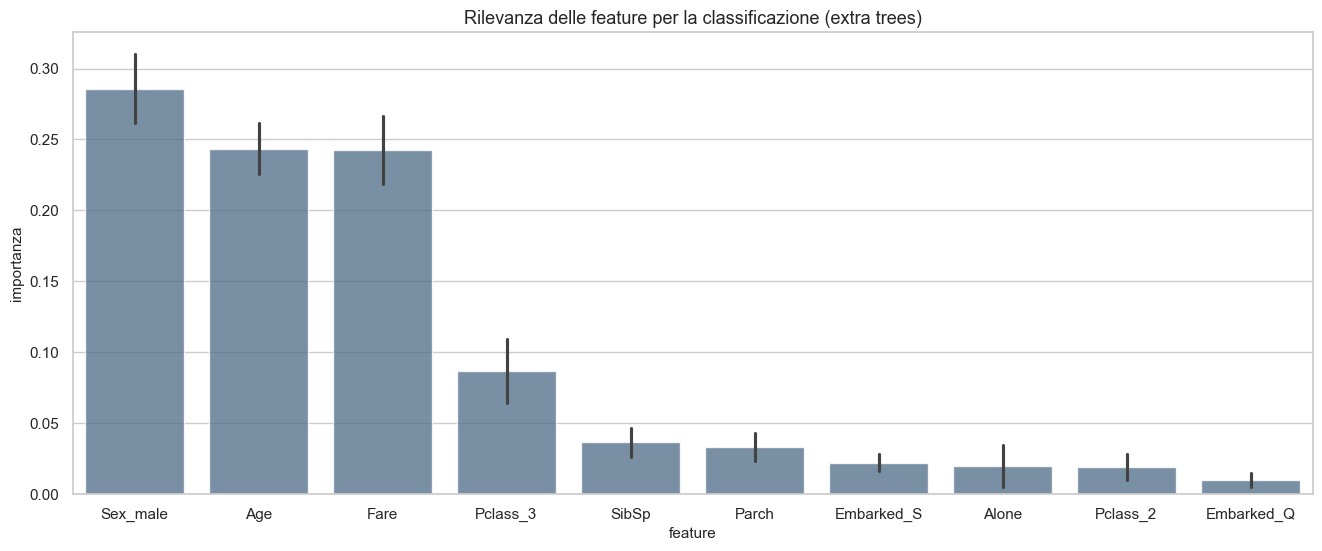

In [32]:
forest = ExtraTreesClassifier(n_estimators=250, random_state=SEED)
forest.fit(X_s, y)
importances = forest.feature_importances_
# importanza delle feature in ciascun albero, in formato "lungo" per seaborn
dd = pd.DataFrame([e.feature_importances_ for e in forest.estimators_], columns=X.columns)
dd_long = dd.melt(var_name='feature', value_name='importanza')
order = dd.mean().sort_values(ascending=False).index

plt.figure(figsize=(16, 6))
sns.barplot(data=dd_long, x='feature', y='importanza', order=order, errorbar='sd', color=colors[8], alpha=.8)
plt.title('Rilevanza delle feature per la classificazione (extra trees)')
plt.show()

Il secondo criterio è la **mutua informazione** tra ciascuna feature e il target, che misura la riduzione dell'incertezza sul target ottenuta conoscendo la feature, e rileva dipendenze di qualunque forma. Il terzo è la statistica $F$ dell'**analisi della varianza** (ANOVA), che confronta le medie della feature nelle due classi rispetto alla variabilità interna a ciascuna: valori grandi, e $p$-value piccoli, indicano feature le cui medie differiscono molto tra sopravvissuti e deceduti. A differenza della mutua informazione, l'ANOVA rileva solo differenze nella media.

In [33]:
mi = mutual_info_classif(X_s, y, random_state=SEED)
fc = SelectKBest(f_classif, k='all').fit(X_s, y)
rank = pd.DataFrame({'mutua informazione': mi, 'F (ANOVA)': fc.scores_, 'p-value': fc.pvalues_}, index=X.columns)
rank.sort_values(by='mutua informazione', ascending=False).round(4)

,mutua informazione,F (ANOVA),p-value
Sex_male,0.1387,372.4057,0.0000
Fare,0.1287,63.0308,0.0000
Pclass_3,0.0670,103.0576,0.0000
Alone,0.0382,38.3537,0.0000
Parch,0.0060,5.9635,0.0148
SibSp,0.0010,1.1106,0.2922
Embarked_Q,0.0006,0.0118,0.9134
Age,0.0000,3.7615,0.0528
Embarked_S,0.0000,20.3745,0.0000
Pclass_2,0.0000,7.8148,0.0053


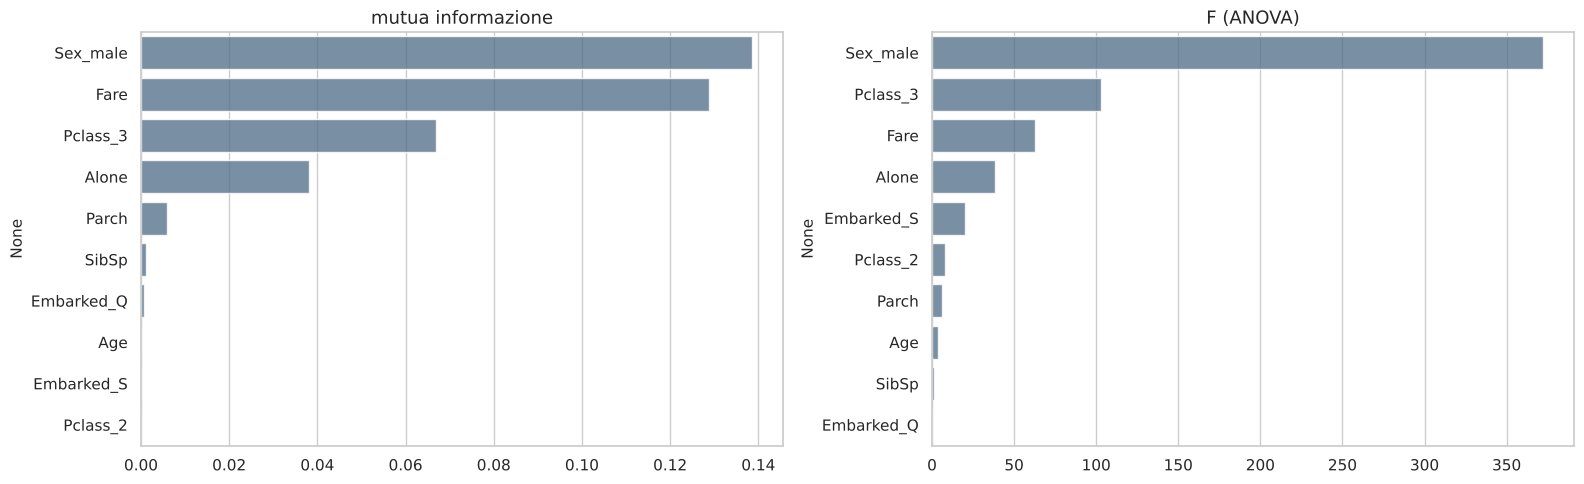

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, col in zip(axes, ['mutua informazione', 'F (ANOVA)']):
    r_ = rank[col].sort_values(ascending=False)
    sns.barplot(x=r_.values, y=r_.index, color=colors[8], alpha=.8, orient='h', ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

I tre criteri concordano nel considerare *Sex_male* la feature più informativa, seguita da *Pclass_3* e *Fare*, e attribuiscono una certa rilevanza ad *Alone*. Differiscono invece su *Age*: gli alberi le danno molta importanza, perché una feature continua permette molte suddivisioni diverse (un noto difetto di questa misura, che favorisce le feature con molti valori), mentre mutua informazione e ANOVA la considerano poco rilevante. L'età media di sopravvissuti e deceduti è infatti simile, e l'effetto dell'età riguarda soprattutto i bambini; inoltre l'imputazione con la mediana ha reso identica l'età del $20\%$ dei passeggeri.

Consideriamo le $5$ feature *Sex_male*, *Pclass_3*, *Fare*, *Alone* e *Age* come quelle che forniscono la maggior parte dell'informazione utile, e definiamo una funzione che le seleziona da una matrice di feature, da inserire in una pipeline.

Si noti che la scelta è stata fatta osservando tutto il dataset: valutando poi il modello con le feature selezionate mediante cross validation sullo stesso dataset, la stima dell'errore risulta leggermente ottimista, perché parte dell'informazione dei fold di test è stata usata per la selezione.

In [34]:
sel_feat = ['Sex_male', 'Pclass_3', 'Fare', 'Alone', 'Age']
X_sel = X_s[sel_feat]
cols = [X.columns.get_loc(c) for c in sel_feat]

def select_columns(X):
    return np.take(X, cols, axis=1)

La dimensionalità del problema si può ridurre anche con l'**estrazione di feature**, ad esempio con l'analisi delle componenti principali (PCA), che sostituisce le feature originali con un numero minore di loro combinazioni lineari, scelte in modo da conservare la maggior parte della varianza dei dati. Il grafico mostra la frazione di varianza spiegata cumulativa al crescere del numero di componenti.

Va ricordato che la PCA non tiene conto del target: le direzioni di massima varianza non sono necessariamente quelle più utili per distinguere le classi.

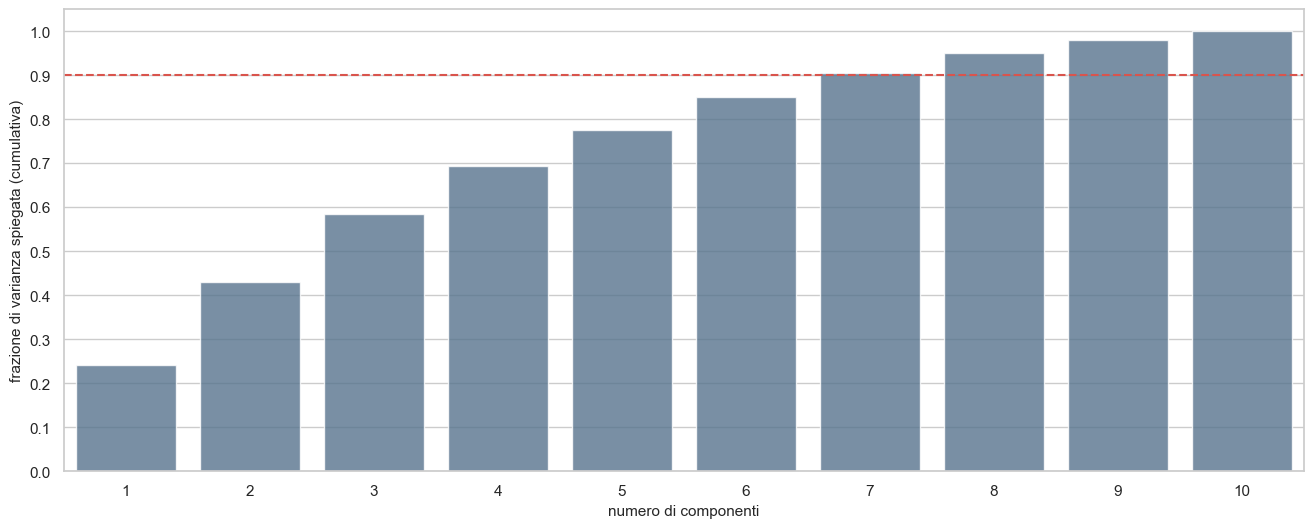

In [35]:
pca = PCA(n_components=X_s.shape[1]).fit(X_s)
evr = pca.explained_variance_ratio_

plt.figure(figsize=(16, 6))
sns.barplot(x=np.arange(1, evr.shape[0]+1), y=evr.cumsum(), color=colors[8], alpha=.8)
plt.axhline(.9, color=colors[2], ls='--')
plt.xlabel('numero di componenti')
plt.ylabel('frazione di varianza spiegata (cumulativa)')
plt.yticks(np.linspace(0, 1, 11))
plt.show()

Con $8$ componenti si conserva più del $90\%$ della varianza.

In [36]:
X_pca = PCA(n_components=8).fit_transform(X_s)
X_pca.shape

(891, 8)

## Classificazione

### Naive Bayes

Il primo classificatore è **Naive Bayes** gaussiano, un classificatore generativo: modella la distribuzione delle feature in ciascuna classe, $p(\mathbf{x}\mid C_k)$, e la probabilità a priori delle classi $p(C_k)$, e ricava la probabilità a posteriori con la regola di Bayes,
$$p(C_k\mid\mathbf{x})=\frac{p(\mathbf{x}\mid C_k)\,p(C_k)}{\sum_j p(\mathbf{x}\mid C_j)\,p(C_j)}.$$
L'ipotesi "ingenua" è che le feature siano **condizionatamente indipendenti** data la classe, $p(\mathbf{x}\mid C_k)=\prod_i p(x_i\mid C_k)$, e nella versione gaussiana ogni $p(x_i\mid C_k)$ è una gaussiana con media e varianza stimate dai dati. Entrambe le ipotesi sono qui violate: le feature binarie della codifica one-hot non sono gaussiane, e feature come *Fare* e *Pclass_3*, o *SibSp*, *Parch* e *Alone*, sono fortemente dipendenti. Naive Bayes funziona spesso bene come classificatore anche quando le ipotesi sono false, ma le **probabilità** che restituisce tendono a essere poco affidabili, concentrate vicino a $0$ e $1$.

Il classificatore viene inserito in una pipeline, dopo la standardizzazione delle feature.

In [37]:
clf = Pipeline([('scaler', StandardScaler()),('classifier', GaussianNB())])

Il classificatore viene addestrato fornendogli il training set $(X,y)$; per ora usiamo tutte le feature e tutto il dataset.

In [38]:
clf = clf.fit(X, y)

I parametri del classificatore (medie e varianze per classe, probabilità a priori) sono ora stimati dal training set, e il classificatore può essere applicato alla predizione. Applichiamolo dapprima al training set stesso (più precisamente, alla sola matrice delle feature $X$).

In [39]:
p = clf.predict(X)

### Misure di qualità

Come si è comportato il classificatore? Le misure che consideriamo si basano sui seguenti conteggi:

- **veri positivi** (TP): passeggeri sopravvissuti (classe 1) classificati correttamente;
- **veri negativi** (TN): passeggeri deceduti (classe 0) classificati correttamente;
- **falsi positivi** (FP): passeggeri deceduti classificati come sopravvissuti;
- **falsi negativi** (FN): passeggeri sopravvissuti classificati come deceduti.

Questi valori sono riportati nella **matrice di confusione** $C$, in cui $C_{ij}$ è il numero di elementi della classe $i$ predetti come appartenenti alla classe $j$: le righe corrispondono alle classi vere, le colonne alle predizioni. In scikit-learn, `confusion_matrix(y_vere, y_predette)` restituisce quindi

In [40]:
print('\n'.join(['\t'.join([str(cell) for cell in row]) for row in [['TN', 'FP'],['FN','TP']]]))

TN	FP
FN	TP


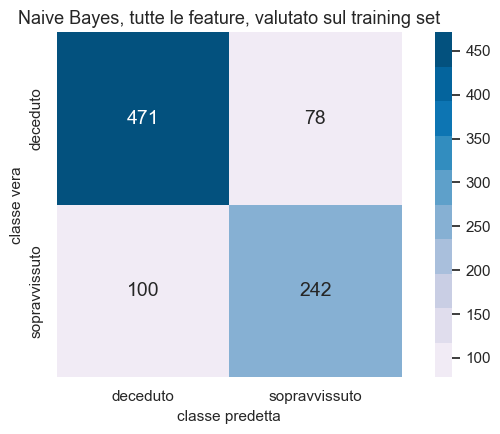

 242 veri positivi
 100 falsi negativi
  78 falsi positivi
 471 veri negativi


In [41]:
cmat = confusion_matrix(y, p)
plot_confusion([cmat], ['Naive Bayes, tutte le feature, valutato sul training set'])
print('{0:4d} veri positivi'.format(cmat[1,1]))
print('{0:4d} falsi negativi'.format(cmat[1,0]))
print('{0:4d} falsi positivi'.format(cmat[0,1]))
print('{0:4d} veri negativi'.format(cmat[0,0]))

A partire da questi conteggi si definiscono le misure di qualità di un classificatore binario:

- la **precision** è la frazione di elementi predetti positivi che sono effettivamente positivi, $P=\frac{TP}{TP+FP}$: qui, la frazione di passeggeri classificati come sopravvissuti che sono effettivamente sopravvissuti;
- la **recall** è la frazione di elementi positivi che sono predetti come positivi, $R=\frac{TP}{TP+FN}$: qui, la frazione di sopravvissuti che il classificatore riconosce come tali;
- l'**F-score** è la media armonica di precision e recall, $F=2\left(P^{-1}+R^{-1}\right)^{-1}=\frac{2PR}{P+R}$, che è alta solo se entrambe sono alte;
- l'**accuratezza** è la frazione di elementi classificati correttamente, $\frac{TP+TN}{TP+TN+FP+FN}$.

Precision e recall sono in tensione tra loro: un classificatore che predice positivi solo i casi più sicuri ha alta precision e bassa recall, uno che predice positivi quasi tutti ha alta recall e bassa precision. Quale delle due privilegiare dipende dai costi dei due tipi di errore nell'applicazione.

In [42]:
print('Precision = {0:5.4f}'.format(precision_score(y, p)))
print('Recall = {0:5.4f}'.format(recall_score(y, p)))
print('F-score = {0:5.4f}'.format(f1_score(y, p)))
print('Accuratezza = {0:5.4f}'.format(accuracy_score(y, p)))

Precision = 0.7562
Recall = 0.7076
F-score = 0.7311
Accuratezza = 0.8002


Le stesse misure possono essere calcolate per entrambe le classi, considerando a turno ciascuna come la classe "positiva": la precision della classe 0, ad esempio, è la frazione di passeggeri predetti deceduti che sono effettivamente deceduti.

In [43]:
report(y, p)

                          precision  recall  F-score  supporto
classe 0 (deceduto)          0.8249  0.8579   0.8411       549
classe 1 (sopravvissuto)     0.7562  0.7076   0.7311       342
Accuratezza = 0.8002


### Probabilità stimate e soglia di decisione

Il modello restituisce, oltre alla classe predetta, una misura di confidenza della predizione: la **probabilità stimata** che il passeggero sia sopravvissuto, $p(C_1\mid\mathbf{x})$. La classe predetta si ottiene confrontando questa probabilità con una **soglia**, per default $0.5$.

Il grafico mostra la distribuzione delle probabilità stimate, separatamente per i passeggeri effettivamente sopravvissuti (1) e deceduti (0): un buon classificatore assegna probabilità alte ai primi e basse ai secondi, e le due distribuzioni sono ben separate. Come anticipato, Naive Bayes concentra le probabilità vicino a $0$ e $1$: il modello è troppo sicuro di sé, una conseguenza dell'ipotesi di indipendenza, che fa contare più volte l'evidenza portata da feature correlate.

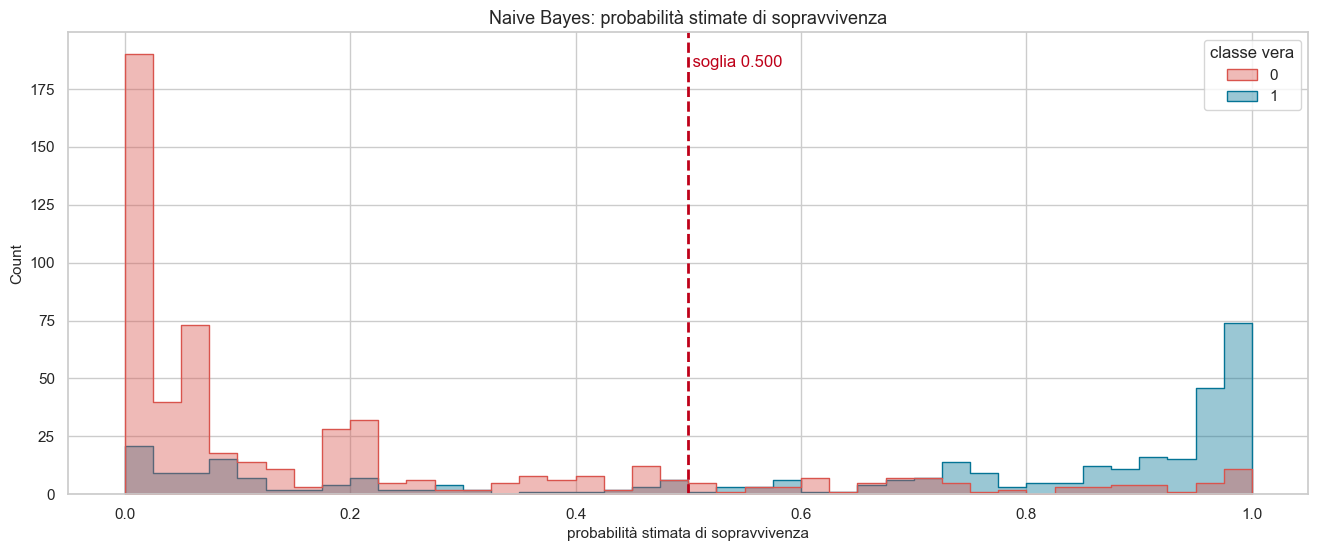

In [44]:
y_prob = clf.predict_proba(X)[:,1]
plot_probabilita(y, y_prob, .5, 'Naive Bayes: probabilità stimate di sopravvivenza')

### Curva ROC

Una curva **ROC** (*Receiver Operating Characteristic*) rappresenta, al variare della soglia applicata alle probabilità, la frazione $\frac{FP}{N}=\frac{FP}{TN+FP}$ di elementi negativi classificati erroneamente come positivi (*false positive rate*, FPR) e la frazione $\frac{TP}{P}=\frac{TP}{TP+FN}$ di elementi positivi classificati correttamente (*true positive rate*, TPR, che coincide con la recall). Con soglia $1$ nessun elemento è predetto positivo, e si è nel punto $(0,0)$; con soglia $0$ tutti lo sono, e si è nel punto $(1,1)$; al diminuire della soglia la curva sale da $(0,0)$ a $(1,1)$.

Il punto ideale è $(0,1)$: nessun negativo classificato erroneamente, tutti i positivi classificati correttamente. La diagonale corrisponde a un classificatore che assegna probabilità a caso.

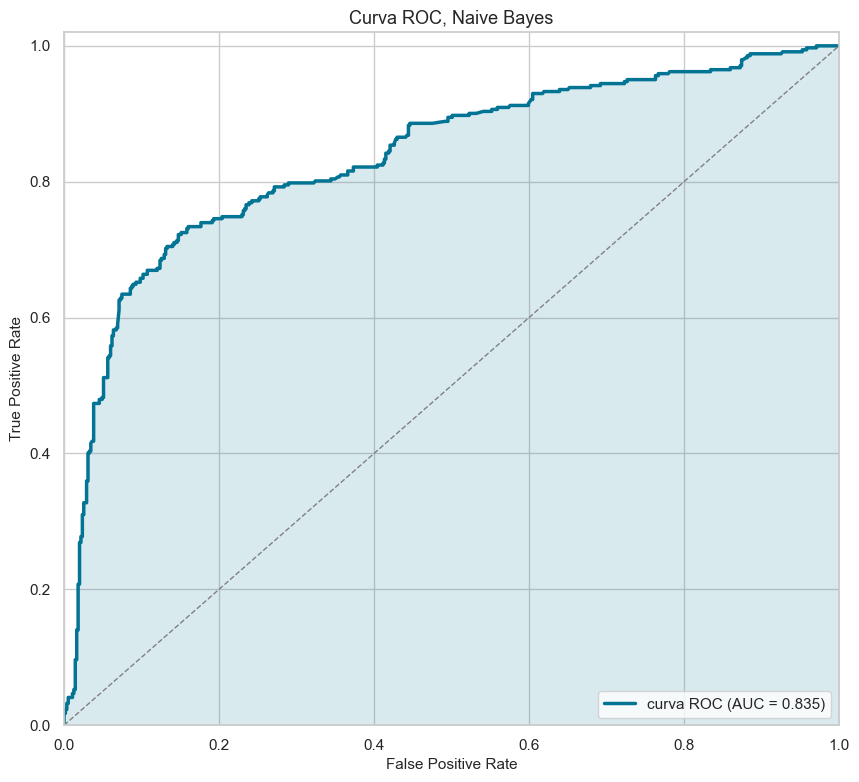

In [45]:
fpr, tpr, thresholds = roc_curve(y, y_prob, pos_label=1)

plt.figure(figsize=(10, 9))
sns.lineplot(x=fpr, y=tpr, color=colors[1], linewidth=2.5, label='curva ROC (AUC = %0.3f)' % auc(fpr, tpr), estimator=None, sort=False)
plt.fill_between(fpr, 0, tpr, color=colors[1], alpha=0.15)
plt.plot([0, 1], [0, 1], color='grey', linestyle='--', linewidth=1)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.02])
plt.ylabel('True Positive Rate')
plt.xlabel('False Positive Rate')
plt.title('Curva ROC, Naive Bayes')
plt.legend(loc="lower right")
plt.show()

L'area sotto la curva (**AUC**, *Area Under Curve*) è una misura della qualità del classificatore indipendente dalla soglia. Più precisamente, è la probabilità che il classificatore assegni a un elemento positivo scelto a caso una probabilità di essere positivo maggiore di quella assegnata a un elemento negativo scelto a caso: misura quindi la capacità di **ordinare** correttamente gli elementi, non l'accuratezza delle probabilità. Vale $1$ per un classificatore perfetto e $0.5$ per uno casuale.

In [46]:
print('AUC = {0:0.4f}'.format(auc(fpr, tpr)))
print('AUC (roc_auc_score) = {0:0.4f}'.format(roc_auc_score(y, y_prob)))

AUC = 0.8353
AUC (roc_auc_score) = 0.8353


La soglia $0.5$ non è necessariamente la migliore. Un criterio comune è la **statistica J di Youden**, che sceglie la soglia che massimizza $TPR-FPR$, cioè il punto della curva ROC più lontano dalla diagonale. È appropriata quando i due tipi di errore hanno costi simili *relativamente alla dimensione delle classi*; in generale, la soglia ottima dipende dai costi dei falsi positivi e dei falsi negativi, come discusso nelle note.

In [47]:
optimal_idx = np.argmax(tpr-fpr)
optimal_threshold = thresholds[optimal_idx]
print('Soglia ottima: {0:3.3f}'.format(optimal_threshold))

Soglia ottima: 0.480


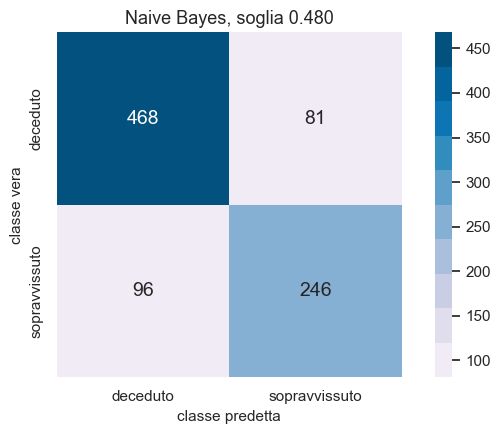

                          precision  recall  F-score  supporto
classe 0 (deceduto)          0.8298  0.8525   0.8410       549
classe 1 (sopravvissuto)     0.7523  0.7193   0.7354       342
Accuratezza = 0.8013


In [48]:
p = (y_prob > optimal_threshold).astype(int)
plot_confusion([confusion_matrix(y, p)], ['Naive Bayes, soglia {0:.3f}'.format(optimal_threshold)])
report(y, p)

Con la nuova soglia, di poco inferiore a $0.5$, la recall della classe 1 aumenta leggermente, al prezzo di una precision di poco minore: il compromesso tra i due tipi di errore si è spostato. Si noti che sia la soglia sia le misure sono calcolate sullo stesso insieme di dati: anche la scelta della soglia è una forma di apprendimento, e andrebbe valutata su dati diversi da quelli usati per farla.

### Valutazione su un test set

Tutte le misure calcolate finora sono state ottenute sul training set, e sono quindi ottimiste. Una valutazione migliore si ottiene separando un training set e un test set. Usiamo una partizione **stratificata** (`stratify=y`), che mantiene in entrambi gli insiemi la stessa proporzione di sopravvissuti del dataset completo.

In [49]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=SEED)
clf = Pipeline([('scaler', StandardScaler()),('classifier', GaussianNB())]).fit(X_train, y_train)

Calcoliamo le predizioni e le misure di qualità sia sul training set sia sul test set.

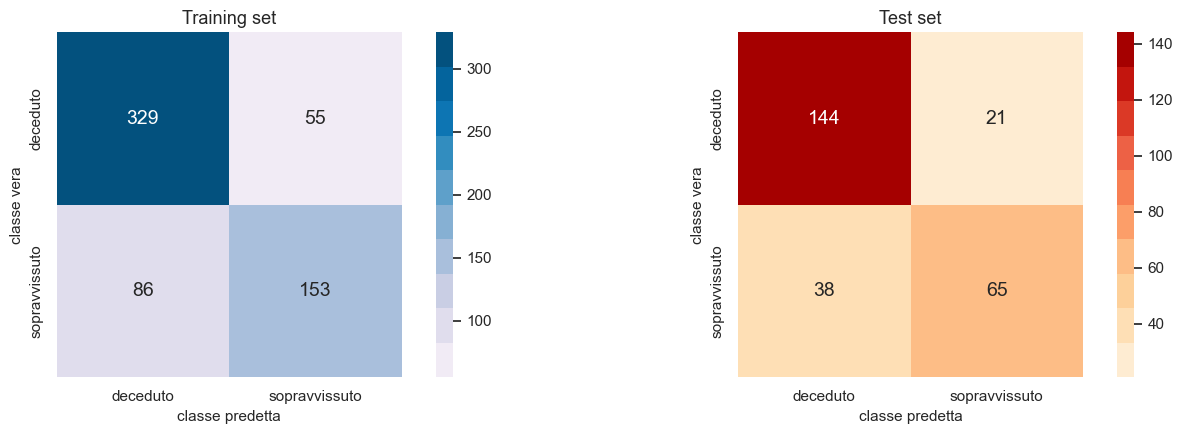

In [50]:
p_train = clf.predict(X_train)
p_test = clf.predict(X_test)
plot_confusion([confusion_matrix(y_train, p_train), confusion_matrix(y_test, p_test)], ['Training set', 'Test set'])

In [51]:
report(y_train, p_train, 'TRAINING SET')
print()
report(y_test, p_test, 'TEST SET')
print()
print('AUC training: {0:3.3f}, AUC test: {1:3.3f}'.format(roc_auc_score(y_train, clf.predict_proba(X_train)[:,1]),
                                                     roc_auc_score(y_test, clf.predict_proba(X_test)[:,1])))

TRAINING SET
                          precision  recall  F-score  supporto
classe 0 (deceduto)          0.7928  0.8568   0.8235       384
classe 1 (sopravvissuto)     0.7356  0.6402   0.6846       239
Accuratezza = 0.7737

TEST SET
                          precision  recall  F-score  supporto
classe 0 (deceduto)          0.7912  0.8727   0.8300       165
classe 1 (sopravvissuto)     0.7558  0.6311   0.6878       103
Accuratezza = 0.7799

AUC training: 0.830, AUC test: 0.808


Le misure sul test set sono simili a quelle sul training set: Naive Bayes ha pochi parametri (una media e una varianza per feature e per classe) e non tende all'overfitting. Le differenze tra le due colonne sono dello stesso ordine delle fluttuazioni dovute alla scelta della partizione, con un test set di soli $268$ elementi.

### Cross validation

Una valutazione più stabile si ottiene con la **cross validation**, qui a $7$ fold. Usiamo una `StratifiedKFold`, che costruisce fold con la stessa proporzione di classi, dopo aver mescolato le righe. La funzione `cross_validate` calcola più misure contemporaneamente, e restituisce per ciascuna i valori sui singoli fold.

In [52]:
cv = StratifiedKFold(n_splits=7, shuffle=True, random_state=SEED)
metriche = ('precision', 'recall', 'accuracy', 'f1', 'roc_auc')

def valuta(clf, X, y, nome):
    """Cross validation con più misure; restituisce le medie sui fold e le memorizza in 'confronto'."""
    scores = cross_validate(estimator=clf, X=X, y=y, cv=cv, scoring=metriche, return_train_score=True)
    medie = {m: scores['test_' + m].mean() for m in metriche}
    confronto[nome] = medie
    print(nome)
    print('  ' + ', '.join('{0}: {1:.3f} (± {2:.3f})'.format(m, scores['test_' + m].mean(), scores['test_' + m].std()) for m in metriche))
    return scores

confronto = {}
scores = valuta(Pipeline([('scaler', StandardScaler()),('classifier', GaussianNB())]), X, y, 'Naive Bayes, tutte le feature')

Naive Bayes, tutte le feature
  precision: 0.729 (± 0.078), recall: 0.699 (± 0.082), accuracy: 0.783 (± 0.055), f1: 0.712 (± 0.073), roc_auc: 0.821 (± 0.051)


Consideriamo ora il dataset ridotto alle $5$ feature selezionate, inserendo la funzione di selezione nella pipeline mediante un `FunctionTransformer`:

In [53]:
clf = Pipeline([('scaler', StandardScaler()),('features', FunctionTransformer(select_columns)),
                ('classifier', GaussianNB())])
scores = valuta(clf, X, y, 'Naive Bayes, 5 feature selezionate')

Naive Bayes, 5 feature selezionate
  precision: 0.708 (± 0.070), recall: 0.661 (± 0.074), accuracy: 0.763 (± 0.045), f1: 0.681 (± 0.060), roc_auc: 0.819 (± 0.055)


E quello ridotto mediante PCA a $8$ componenti. La PCA è inserita nella pipeline, e viene quindi stimata in ogni fold sul solo training set:

In [54]:
clf = Pipeline([('scaler', StandardScaler()),('features', PCA(n_components=8)),
                ('classifier', GaussianNB())])
scores = valuta(clf, X, y, 'Naive Bayes, PCA (8 componenti)')

Naive Bayes, PCA (8 componenti)
  precision: 0.769 (± 0.076), recall: 0.626 (± 0.070), accuracy: 0.782 (± 0.042), f1: 0.688 (± 0.059), roc_auc: 0.816 (± 0.062)


Ridurre le feature non migliora le prestazioni di Naive Bayes: l'AUC resta circa $0.82$ in tutti e tre i casi, con differenze molto minori della variabilità tra i fold. Con le $5$ feature selezionate accuratezza, precision e recall diminuiscono leggermente: le feature eliminate portavano comunque un po' di informazione. Con la PCA, le cui componenti sono **non correlate** per costruzione, il modello rispetta meglio l'ipotesi di indipendenza: la precision aumenta e la recall diminuisce, cioè il classificatore diventa più prudente nel predire la sopravvivenza, mentre la capacità complessiva di ordinare i passeggeri (l'AUC) non cambia. È un risultato frequente: Naive Bayes è spesso un buon classificatore anche quando le sue ipotesi sono violate, perché per classificare correttamente basta che le probabilità a posteriori siano ordinate nel modo giusto, non che siano accurate.

Esaminiamo il modello con PCA addestrato su tutto il dataset: probabilità stimate, soglia ottima e matrice di confusione.

Soglia ottima: 0.374


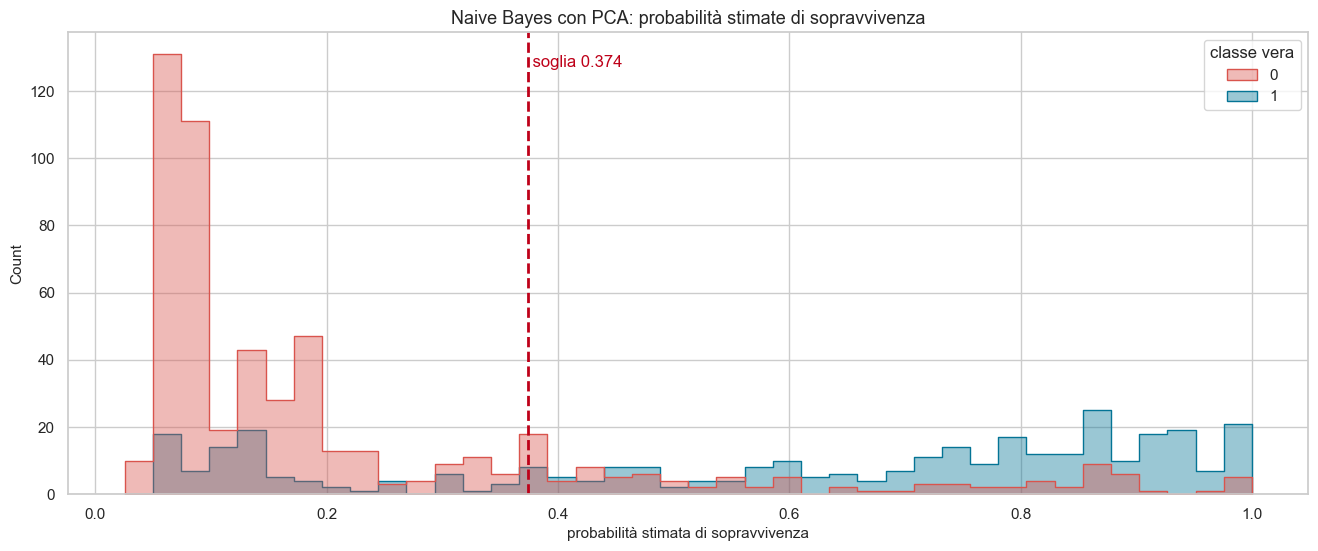

In [55]:
clf = clf.fit(X, y)
y_prob = clf.predict_proba(X)[:,1]
fpr, tpr, thresholds = roc_curve(y, y_prob, pos_label=1)
optimal_threshold = thresholds[np.argmax(tpr-fpr)]
p = (y_prob > optimal_threshold).astype(int)
print('Soglia ottima: {0:3.3f}'.format(optimal_threshold))
plot_probabilita(y, y_prob, optimal_threshold, 'Naive Bayes con PCA: probabilità stimate di sopravvivenza')

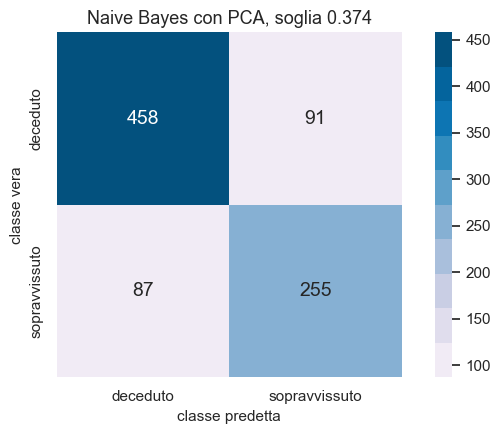

                          precision  recall  F-score  supporto
classe 0 (deceduto)          0.8404  0.8342   0.8373       549
classe 1 (sopravvissuto)     0.7370  0.7456   0.7413       342
Accuratezza = 0.8002


In [56]:
plot_confusion([confusion_matrix(y, p)], ['Naive Bayes con PCA, soglia {0:.3f}'.format(optimal_threshold)])
report(y, p)

### Regressione logistica

La **regressione logistica** è un classificatore discriminativo: modella direttamente la probabilità a posteriori della classe positiva come funzione sigmoide di una combinazione lineare delle feature,
$$p(C_1\mid\mathbf{x})=\sigma(\mathbf{w}^T\mathbf{x}+w_0)=\frac{1}{1+e^{-(\mathbf{w}^T\mathbf{x}+w_0)}},$$
e stima i coefficienti massimizzando la verosimiglianza dei dati, cioè minimizzando la **cross-entropia**. Non fa ipotesi sulla distribuzione delle feature, e non soffre quindi della dipendenza tra di esse come Naive Bayes; la frontiera di decisione è un iperpiano nello spazio delle feature.

In [57]:
clf = Pipeline([('scaler', StandardScaler()),('classifier', LogisticRegression())])
scores = valuta(clf, X, y, 'Regressione logistica, tutte le feature')

Regressione logistica, tutte le feature
  precision: 0.761 (± 0.063), recall: 0.702 (± 0.066), accuracy: 0.799 (± 0.039), f1: 0.728 (± 0.052), roc_auc: 0.851 (± 0.037)


La regressione logistica ottiene un'accuratezza e un'AUC migliori di Naive Bayes con tutte le feature. Uno dei vantaggi del modello è l'interpretabilità: con feature standardizzate, ciascun coefficiente $w_i$ indica di quanto varia il **logaritmo dell'odds** di sopravvivenza, $\log\frac{p(C_1\mid\mathbf{x})}{1-p(C_1\mid\mathbf{x})}$, per un aumento di una deviazione standard della feature, a parità delle altre. Il coefficiente più grande in valore assoluto è, come atteso, quello di *Sex_male*, negativo.

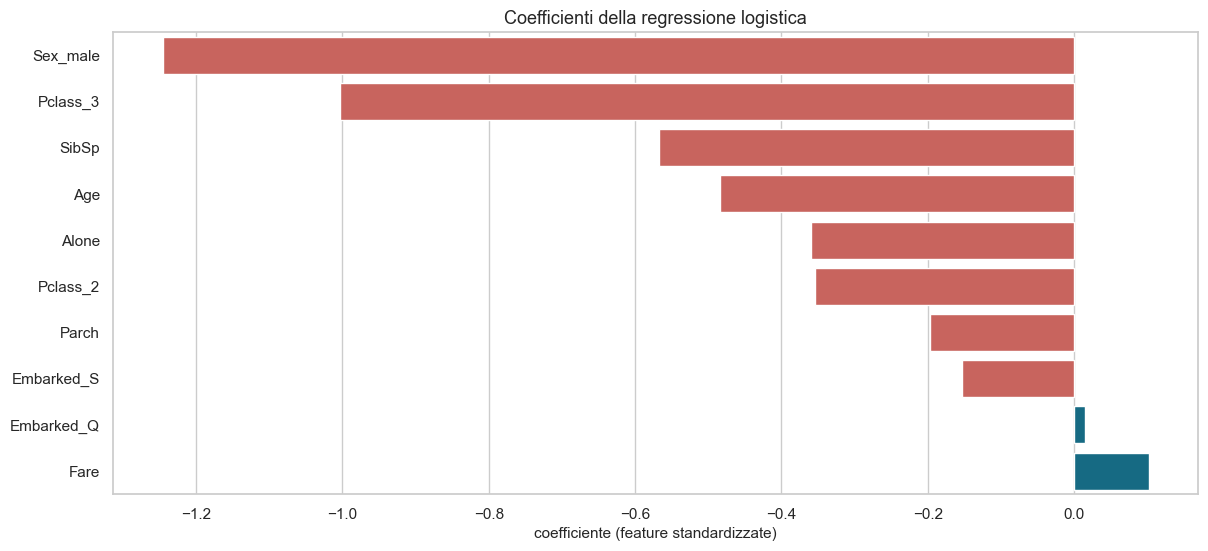

In [58]:
clf = clf.fit(X, y)
coef = pd.Series(clf.named_steps['classifier'].coef_[0], index=X.columns).sort_values()
plt.figure(figsize=(14, 6))
sns.barplot(x=coef.values, y=coef.index, hue=coef.values > 0, palette={True: colors[1], False: colors[2]}, legend=False, orient='h')
plt.xlabel('coefficiente (feature standardizzate)')
plt.ylabel('')
plt.title('Coefficienti della regressione logistica')
plt.show()

Soglia ottima: 0.359


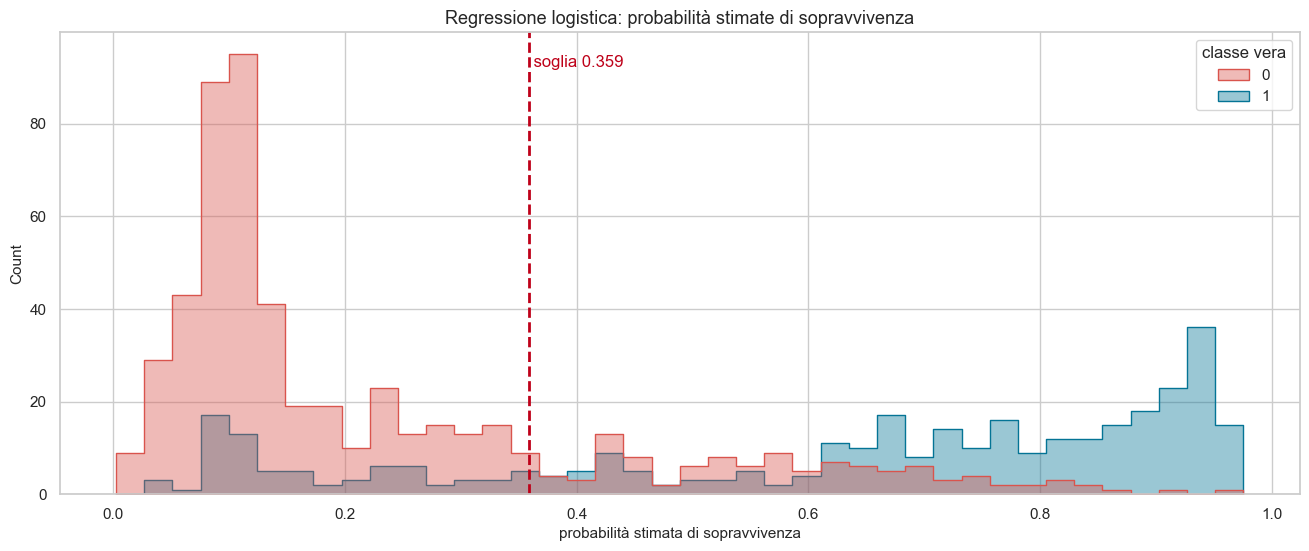

In [59]:
y_prob = clf.predict_proba(X)[:,1]
fpr, tpr, thresholds = roc_curve(y, y_prob, pos_label=1)
optimal_threshold = thresholds[np.argmax(tpr-fpr)]
p = (y_prob > optimal_threshold).astype(int)
print('Soglia ottima: {0:3.3f}'.format(optimal_threshold))
plot_probabilita(y, y_prob, optimal_threshold, 'Regressione logistica: probabilità stimate di sopravvivenza')

A differenza di Naive Bayes, le probabilità stimate dalla regressione logistica sono distribuite su tutto l'intervallo $[0,1]$: il modello esprime incertezza per i passeggeri dalle caratteristiche intermedie.

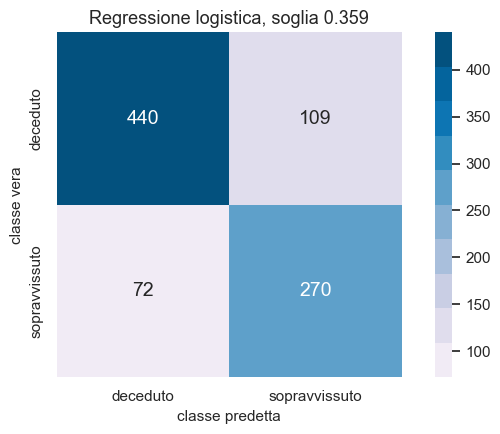

                          precision  recall  F-score  supporto
classe 0 (deceduto)          0.8594  0.8015   0.8294       549
classe 1 (sopravvissuto)     0.7124  0.7895   0.7490       342
Accuratezza = 0.7969


In [60]:
plot_confusion([confusion_matrix(y, p)], ['Regressione logistica, soglia {0:.3f}'.format(optimal_threshold)])
report(y, p)

### Calibrazione delle probabilità

Un classificatore probabilistico è **calibrato** se, tra gli elementi a cui assegna probabilità $q$ di essere positivi, la frazione di positivi è effettivamente circa $q$. La calibrazione si verifica con un **diagramma di affidabilità**: le probabilità predette sono raggruppate in intervalli, e per ciascun intervallo si confronta la probabilità media predetta con la frazione osservata di positivi. Un classificatore calibrato ha i punti lungo la diagonale.

Per evitare di valutare la calibrazione sugli stessi dati usati per l'apprendimento, usiamo le probabilità **out-of-fold** prodotte da `cross_val_predict`: ogni elemento riceve la probabilità stimata dal modello addestrato sui fold che non lo contengono. La regressione logistica, che minimizza la cross-entropia, una loss propria, è ben calibrata; Naive Bayes con tutte le feature è invece troppo sicuro, con frequenze osservate meno estreme delle probabilità predette.

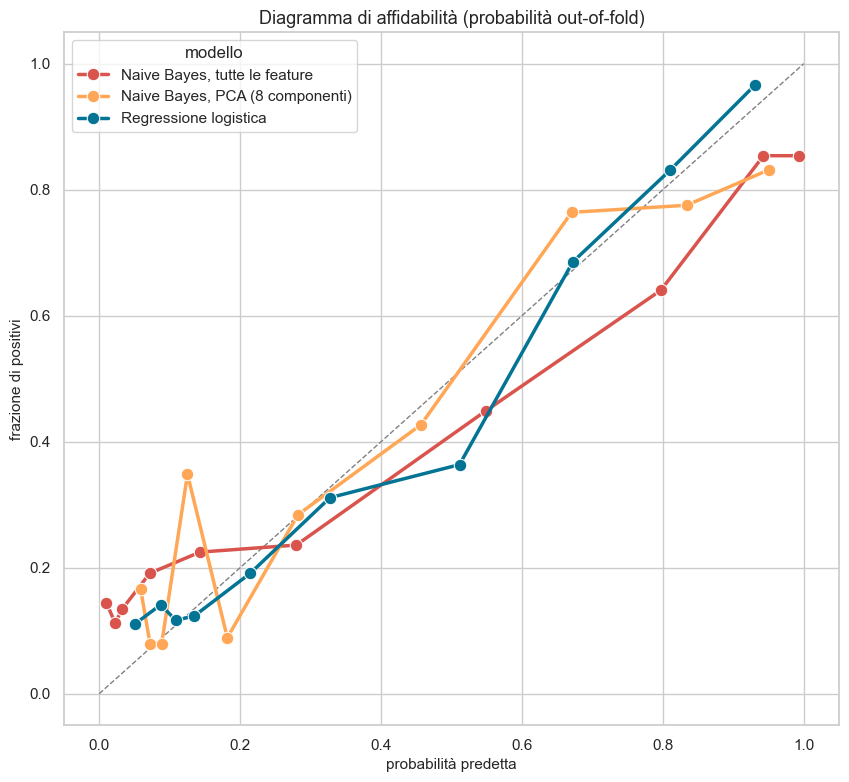

In [61]:
modelli = {
    'Naive Bayes, tutte le feature': Pipeline([('scaler', StandardScaler()),('classifier', GaussianNB())]),
    'Naive Bayes, PCA (8 componenti)': Pipeline([('scaler', StandardScaler()),('features', PCA(n_components=8)),('classifier', GaussianNB())]),
    'Regressione logistica': Pipeline([('scaler', StandardScaler()),('classifier', LogisticRegression())]),
}
oof = {nome: cross_val_predict(m, X, y, cv=cv, method='predict_proba')[:,1] for nome, m in modelli.items()}

calib = []
for nome, prob in oof.items():
    frac_pos, mean_pred = calibration_curve(y, prob, n_bins=10, strategy='quantile')
    calib += [[nome, mp, fp] for mp, fp in zip(mean_pred, frac_pos)]
calib = pd.DataFrame(calib, columns=['modello', 'probabilità predetta', 'frazione di positivi'])

plt.figure(figsize=(10, 9))
plt.plot([0, 1], [0, 1], color='grey', ls='--', lw=1)
sns.lineplot(data=calib, x='probabilità predetta', y='frazione di positivi', hue='modello', marker='o',
             palette=[colors[2], colors[0], colors[1]], linewidth=2.5, markersize=9)
plt.title('Diagramma di affidabilità (probabilità out-of-fold)')
plt.show()

Le curve ROC calcolate sulle stesse probabilità out-of-fold permettono un confronto corretto tra i modelli:

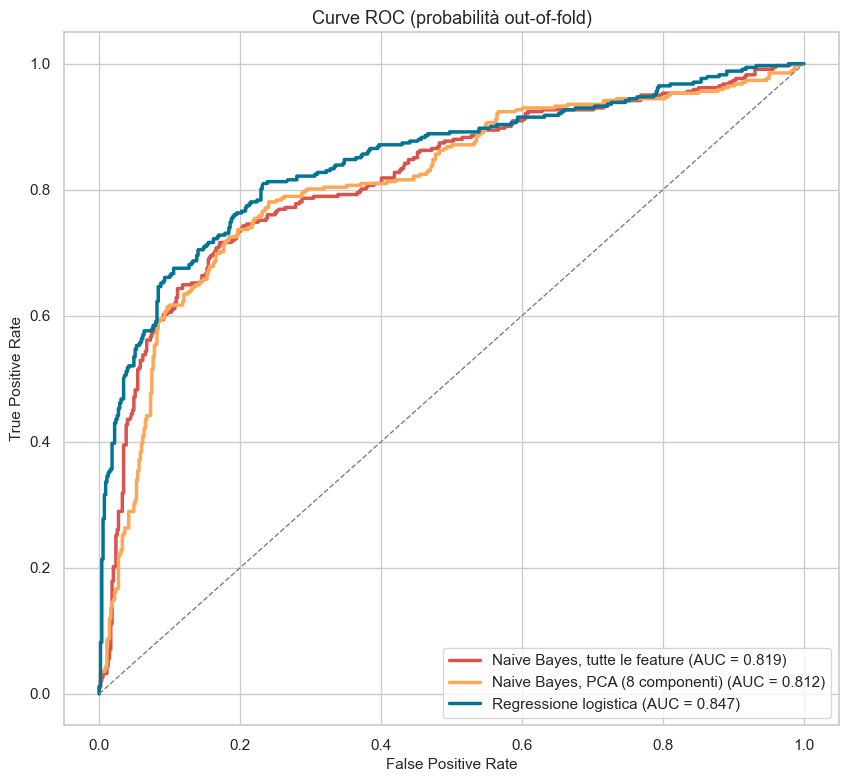

In [62]:
roc = []
for (nome, prob), c in zip(oof.items(), [colors[2], colors[0], colors[1]]):
    fpr, tpr, _ = roc_curve(y, prob)
    roc.append(pd.DataFrame({'FPR': fpr, 'TPR': tpr, 'modello': '{0} (AUC = {1:.3f})'.format(nome, auc(fpr, tpr))}))
roc = pd.concat(roc, ignore_index=True)
plt.figure(figsize=(10, 9))
sns.lineplot(data=roc, x='FPR', y='TPR', hue='modello', estimator=None, sort=False, palette=[colors[2], colors[0], colors[1]], linewidth=2.5)
plt.plot([0, 1], [0, 1], color='grey', ls='--', lw=1)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Curve ROC (probabilità out-of-fold)')
plt.legend(loc='lower right')
plt.show()

### Regolarizzazione

Introduciamo nella regressione logistica un termine di **regolarizzazione**, come per la regressione lineare. scikit-learn minimizza
$$C\sum_{i=1}^n \ell\bigl(t_i,\sigma(\mathbf{w}^T\mathbf{x}_i+w_0)\bigr)+R(\mathbf{w}),$$
dove $\ell$ è la cross-entropia e $R$ è la penalità, L1 ($\|\mathbf{w}\|_1$) o L2 ($\frac12\|\mathbf{w}\|_2^2$). Il coefficiente $C$ moltiplica il termine di errore invece della penalità: è l'**inverso** del coefficiente di regolarizzazione $\lambda$ delle note, per cui valori **piccoli** di $C$ corrispondono a una regolarizzazione **forte**. Nota bene: per default `LogisticRegression` usa già una penalità L2 con $C=1$, e il modello della sezione precedente era quindi già (debolmente) regolarizzato.

Cerchiamo il valore migliore di $C$ e il tipo di penalità con `GridSearchCV`, valutando due misure, AUC e accuratezza, e scegliendo il modello con AUC massima (`refit='AUC'`). Poiché l'effetto di $C$ dipende dal suo ordine di grandezza, usiamo una griglia **logaritmica**, che sostituisce le tre griglie lineari successive, via via più strette, del notebook originale.

In [63]:
domain = np.logspace(-3, 2, 60)
param_grid = [{'classifier__C': domain, 'classifier__penalty': ['l1', 'l2']}]
scoring = {'AUC': 'roc_auc', 'Accuracy': make_scorer(accuracy_score)}
pipe = Pipeline([('scaler', StandardScaler()),('classifier', LogisticRegression(solver='liblinear'))])

gs = GridSearchCV(pipe, param_grid, cv=cv, scoring=scoring, refit='AUC', return_train_score=True)
gs = gs.fit(X, y)
df_results = pd.DataFrame(gs.cv_results_)
print('Migliori parametri (AUC): {0}, AUC = {1:.4f}'.format(gs.best_params_, gs.best_score_))

Migliori parametri (AUC): {'classifier__C': np.float64(0.13141473626117553), 'classifier__penalty': 'l2'}, AUC = 0.8514


Il grafico mostra, per le due penalità, l'AUC e l'accuratezza sul training set (tratteggiate) e nella cross validation (continue) al variare di $C$, con le bande di una deviazione standard sui fold.

- Per $C$ molto piccolo la regolarizzazione è così forte che i coefficienti sono (quasi) nulli e il classificatore predice sempre la classe più frequente: l'accuratezza scende al $62\%$ e, con la penalità L1, che annulla tutti i coefficienti, l'AUC scende a $0.5$.
- Al crescere di $C$ le prestazioni aumentano rapidamente e poi si stabilizzano: oltre $C\approx 0.1$ la regolarizzazione ha un effetto trascurabile.
- La distanza tra le curve di training e di test è piccola per ogni valore di $C$: con $891$ elementi e $12$ feature la regressione logistica non va in overfitting, e la regolarizzazione porta al più un guadagno modesto.

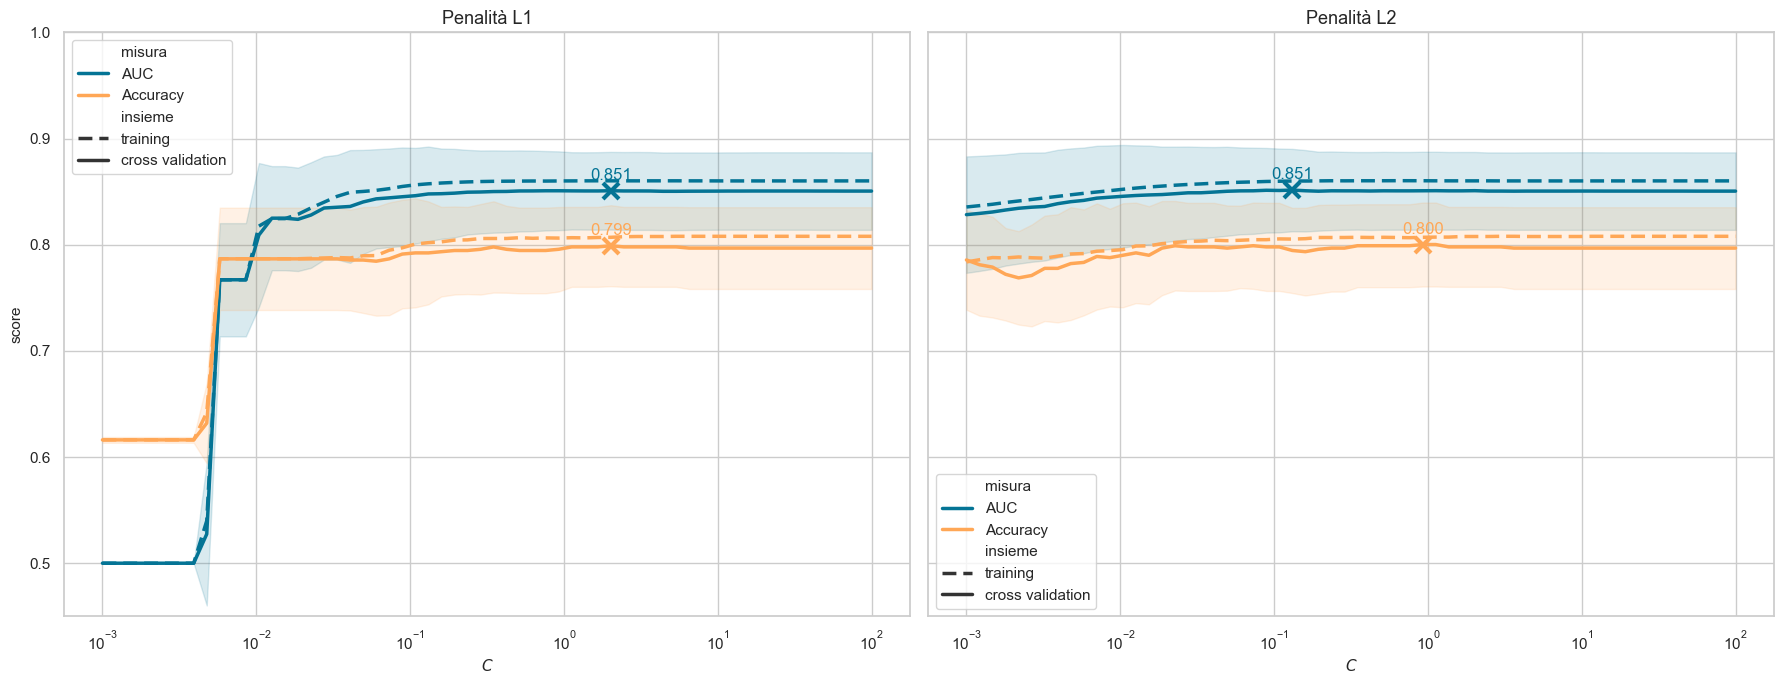

In [64]:
long = []
for scorer in ('AUC', 'Accuracy'):
    for sample in ('train', 'test'):
        d = df_results[['param_classifier__C', 'param_classifier__penalty']].copy()
        d['score'] = df_results['mean_%s_%s' % (sample, scorer)]
        d['std'] = df_results['std_%s_%s' % (sample, scorer)]
        d['misura'] = scorer
        d['insieme'] = 'training' if sample == 'train' else 'cross validation'
        long.append(d)
long = pd.concat(long, ignore_index=True)
long['C'] = long['param_classifier__C'].astype(float)

fig, axes = plt.subplots(1, 2, figsize=(18, 7), sharey=True)
for ax, pen in zip(axes, ['l1', 'l2']):
    d = long[long.param_classifier__penalty == pen]
    sns.lineplot(data=d, x='C', y='score', hue='misura', style='insieme', palette=[colors[1], colors[0]],
                 dashes={'training': (4, 2), 'cross validation': ''}, linewidth=2.5, ax=ax)
    for (mis, ins), g in d[d.insieme == 'cross validation'].groupby(['misura', 'insieme']):
        c = colors[1] if mis == 'AUC' else colors[0]
        ax.fill_between(g['C'], g['score']-g['std'], g['score']+g['std'], color=c, alpha=.15)
        best = g.loc[g['score'].idxmax()]
        ax.plot(best['C'], best['score'], marker='x', color=c, ms=12, mew=3)
        ax.annotate('%0.3f' % best['score'], (best['C'], best['score'] + 0.01), color=c, ha='center')
    ax.set_xscale('log')
    ax.set_xlabel('$C$')
    ax.set_title('Penalità {0}'.format(pen.upper()))
axes[0].set_ylim(.45, 1)
plt.tight_layout()
plt.show()

Il percorso dei coefficienti al variare di $C$, con penalità L1, mostra l'ordine in cui le feature entrano nel modello al diminuire della regolarizzazione: la prima è *Sex_male*, seguita da *Pclass_3*, coerentemente con l'analisi di rilevanza delle feature.

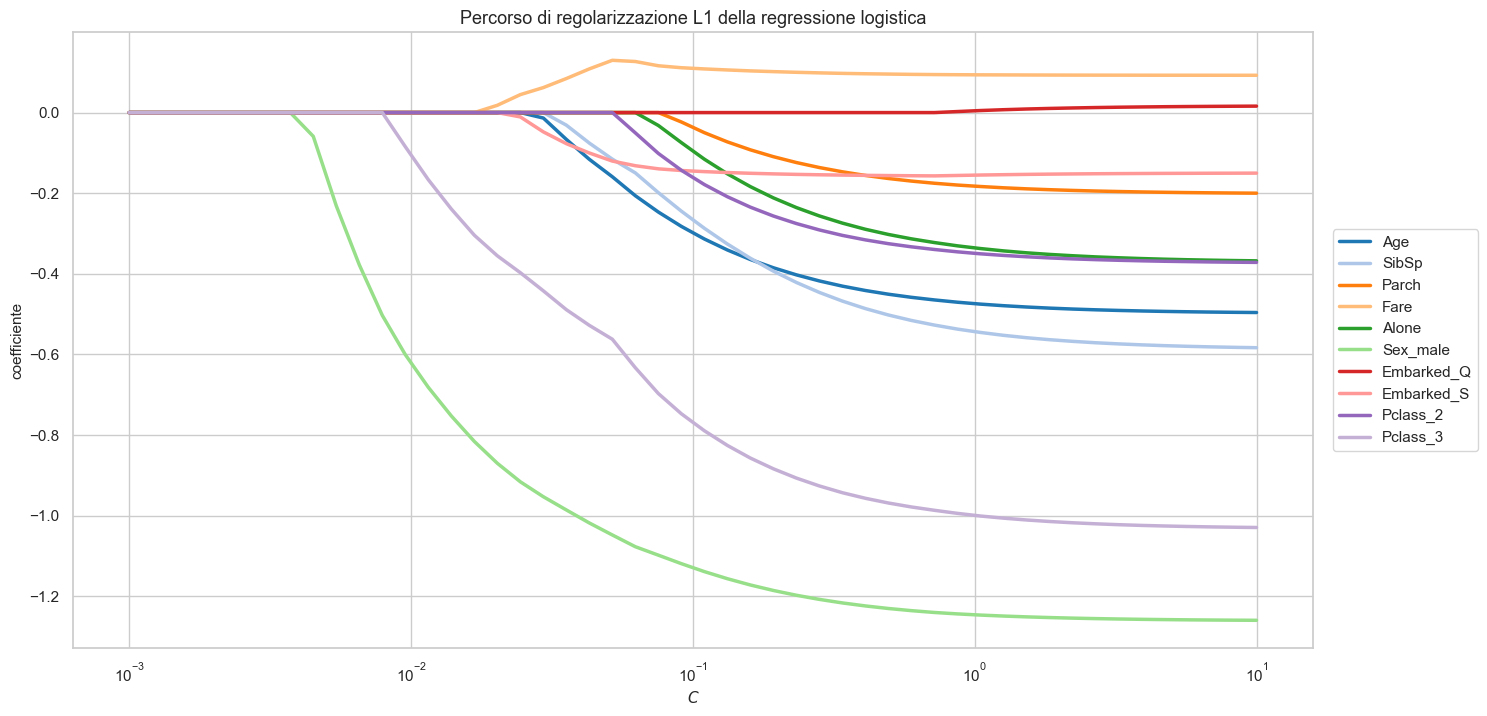

In [65]:
paths = []
for c_ in np.logspace(-3, 1, 50):
    m = Pipeline([('scaler', StandardScaler()),('classifier', LogisticRegression(penalty='l1', C=c_, solver='liblinear'))]).fit(X, y)
    paths += [[c_, f_, w_] for f_, w_ in zip(X.columns, m.named_steps['classifier'].coef_[0])]
paths = pd.DataFrame(paths, columns=['C', 'feature', 'coefficiente'])

plt.figure(figsize=(16, 8))
sns.lineplot(data=paths, x='C', y='coefficiente', hue='feature', palette='tab20', linewidth=2.5)
plt.xscale('log')
plt.xlabel('$C$')
plt.title('Percorso di regolarizzazione L1 della regressione logistica')
plt.legend(loc='center left', bbox_to_anchor=(1.01, .5))
plt.show()

Valutiamo il modello con i parametri scelti, mediante la stessa cross validation usata per gli altri modelli. Come per la soglia, la stima è leggermente ottimista, perché i parametri sono stati scelti osservando gli stessi fold.

In [66]:
best = Pipeline([('scaler', StandardScaler()),
                 ('classifier', LogisticRegression(solver='liblinear', penalty=gs.best_params_['classifier__penalty'],
                                                   C=gs.best_params_['classifier__C']))])
scores = valuta(best, X, y, 'Regressione logistica regolarizzata ({0}, C={1:.3f})'.format(
    gs.best_params_['classifier__penalty'].upper(), gs.best_params_['classifier__C']))

Regressione logistica regolarizzata (L2, C=0.131)
  precision: 0.756 (± 0.065), recall: 0.693 (± 0.071), accuracy: 0.795 (± 0.040), f1: 0.721 (± 0.054), roc_auc: 0.851 (± 0.039)


## Confronto finale

Riassumiamo le misure ottenute in cross validation dai modelli considerati. Alcune osservazioni conclusive:

- tutti i modelli superano nettamente il classificatore banale (accuratezza $0.62$, AUC $0.5$);
- le tre varianti di Naive Bayes hanno prestazioni simili: ridurre le feature, per selezione o con la PCA, sposta il compromesso tra precision e recall ma non migliora l'AUC;
- la regressione logistica ottiene i risultati migliori in termini di AUC e accuratezza, e fornisce in più probabilità ben calibrate e coefficienti interpretabili;
- la regolarizzazione cambia poco: le differenze tra le varianti sono dello stesso ordine della variabilità tra i fold, riportata nelle celle precedenti;
- la scelta della soglia, infine, non cambia la qualità del modello, misurata dall'AUC, ma solo il punto della curva ROC in cui si opera, e va fatta in base ai costi dei due tipi di errore.

In [67]:
tab = pd.DataFrame(confronto).T
tab.round(3)

,precision,recall,accuracy,f1,roc_auc
"Naive Bayes, tutte le feature",0.729,0.699,0.783,0.712,0.821
"Naive Bayes, 5 feature selezionate",0.708,0.661,0.763,0.681,0.819
"Naive Bayes, PCA (8 componenti)",0.769,0.626,0.782,0.688,0.816
"Regressione logistica, tutte le feature",0.761,0.702,0.799,0.728,0.851
"Regressione logistica regolarizzata (L2, C=0.131)",0.756,0.693,0.795,0.721,0.851


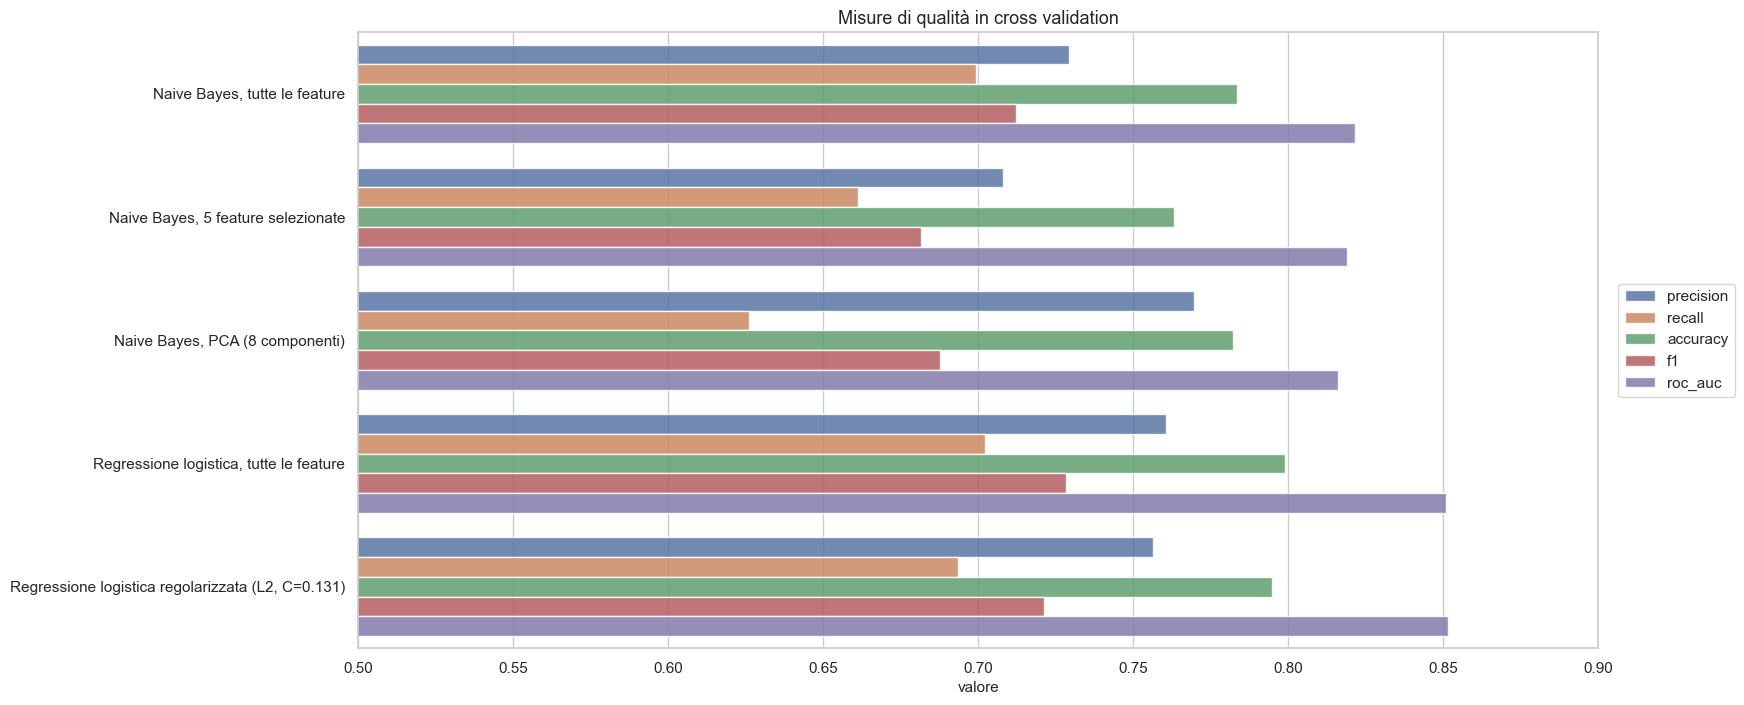

In [68]:
long = tab.reset_index().melt(id_vars='index', var_name='misura', value_name='valore').rename(columns={'index': 'modello'})
plt.figure(figsize=(16, 8))
sns.barplot(data=long, x='valore', y='modello', hue='misura', orient='h', alpha=.85)
plt.xlim(.5, .9)
plt.ylabel('')
plt.title('Misure di qualità in cross validation')
plt.legend(loc='center left', bbox_to_anchor=(1.01, .5))
plt.show()